In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as st
import pickle

import warnings

from tqdm.notebook import tqdm
from scipy.stats import beta
from scipy import stats
from scipy import integrate
from scipy import special
from matplotlib.backends.backend_pdf import PdfPages

In [2]:
#Simulation_itelation

rep_sim = 1000
rep_sim = 100000
rep_sim = 445*10**3

In [3]:
# Difinition of Runge-Kutta methods

def rk4 ( y, t, h, f ):
    k1 = h * f( y, t )
    k2 = h * f( y + k1/2, t + h/2 )
    k3 = h * f( y + k2/2, t + h/2 )
    k4 = h * f( y + k3, t + h )
    return  y + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h

In [4]:
# Seed definitions

def SEEDS(seed):
    seeds = seed
    if seeds > 2**32 - 1:
        seeds = seeds/0.9 - 2**32
        if seeds > 2**32 - 1:
            seeds = seeds/0.9 - 2**32
            if seeds > 2**32 - 1:
                seeds = seeds/0.9 - 2**32
    np.random.seed(round(seeds))
    DecidedSeed = np.random.randint(0, 2**32)
    return DecidedSeed

In [5]:
# Difinition of PERT distribution

def PERT(a,b,c):
    return a+(c-a)*np.random.beta(1+4*(b-a)/(c-a), 1+4*(c-b)/(c-a))

In [6]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (Normal dist.)
#メトロポリスヘイスティング (正規分布)
def Metropolis_Hastings_norm(Temp_mean, sigma_Temp, Time_end, Temp0):
    Time_end = round(Time_end,1)
    def f(x):
        return stats.norm.pdf(x, Temp_mean, sigma_Temp)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    y = Temp0
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [7]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (PERT dist.)
#メトロポリスヘイスティング　（PERT分布）
def Metropolis_Hastings_pert(Temp_min, Temp_med, Temp_max, Time_end, Temp0):
    Time_end = round(Time_end,1)
    alpha = 1+4*(Temp_med-Temp_min)/(Temp_max-Temp_min)
    beta = 1+4*(Temp_max-Temp_med)/(Temp_max-Temp_min)

    def f(x):
        x_pert = (x - Temp_min)/(Temp_max-Temp_min)
        return stats.beta.pdf(x_pert, alpha, beta)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    
    if Temp0 > Temp_max:
        Temp0pert = Temp_max
    if Temp0 < Temp_min:
        Temp0pert = Temp_min
    else:
        Temp0pert = Temp0
    
    y = Temp0pert
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [8]:
def ROUND4(Value):
    if np.abs(Value) == float('inf'):
        RT = Value
    else:
        log = -np.log10(np.abs(Value))
        if log == float('inf'):
            RT = Value
        if log == -float('inf'):
            RT = Value
        else:
            if Value > 0:
                log = round(log)
                Tlog = log + 4
                RT = round(Value, Tlog)
            if Value < 0:
                log = round(log)
                Tlog = log + 4
                RT = round(Value, Tlog)
    return RT

In [9]:
def Mass_lettuce():  # This study
    return PERT(300, 480, 650)

In [10]:
def Prev_Init_Letuce(m_lettuce):
    # Prevalence (FSant ’Ana et al., 2014)
    Pre_P = np.random.beta(27+1,1181-27+1-1+1)
    CheckLettuceContami = np.random.binomial(n = 1, p = Pre_P)
    
    # Initial Count (logCFU/g) (Sant’ Ana et al., 2011 & Sant’ Ana, Igarashi et al., 2012)
    logC_initial = PERT(-3, -1.4, 1.10)
    
    if CheckLettuceContami == 0:
        logC_initial = -float('inf')
    
    return Pre_P, CheckLettuceContami, logC_initial # (-), logcfu/g

In [11]:
def Prev_Init_Meat():
    ID_choice = 0
    if ID_choice == 0:
        # Prevalence Overview of Listeria monocytogenes contamination in Japan
        Pre_P = np.random.choice([0.11, 0.12, 0.30, 0.30, 0.19])
        CheckMeatContami = np.random.binomial(n = 1, p = Pre_P)

        # Initial Count (log CFU/g) International Journal of Food Microbiology 379 (2022) 109843
        X = [-3, -1.4, 1.6, 2]
        P = [0, 0.2, 0.3, 1]

        p = np.random.uniform(np.min(P), np.max(P))

        for i in range(len(P)):
            if not i==np.max(range(len(P))):
                if ((P[i]<= p)&(p<P[i+1])):
                    logC_initial = np.random.uniform(X[i], X[i+1])
        if CheckMeatContami == 0:
            logC_initial = -float('inf')
    
    
    return Pre_P, CheckMeatContami, logC_initial # (-), logcfu/g

In [12]:
# Time_temp history is observed by Koseki&Isobe (2005)
Time_temp_trans_reference = pd.read_csv("data/transportation/Temperature_histroy_1.csv")

In [13]:
Temp_ref_trans = Time_temp_trans_reference["Temp_cool"]
Temp_ref_min_trans = np.min(Temp_ref_trans)
Temp_ref_med_trans = np.median(Temp_ref_trans)
Temp_ref_max_trans = np.max(Temp_ref_trans)

In [14]:
print(Temp_ref_min_trans)
print(Temp_ref_med_trans)
print(Temp_ref_max_trans)

1.5
6.5
16.7


In [15]:
def Temp_trans(Time_end):
    Temp0 = PERT(Temp_ref_min_trans, Temp_ref_med_trans, Temp_ref_max_trans)
    return Metropolis_Hastings_pert(Temp_ref_min_trans, Temp_ref_med_trans, Temp_ref_max_trans, Time_end, Temp0)#Koseki et al., 2005

In [16]:
def Time_trans():
    return np.random.uniform(30, 63) #Koseki et al., 2005

In [17]:
def Temp_home(Time_end, Temp0):
    return Metropolis_Hastings_norm(3.45, 2.44, Time_end, Temp0) # Pang et al., 2017

In [18]:
def Time_home():
    return  PERT(12, 48, 168) #Storage at home (Ding et al., 2013)

In [19]:
sm_growth_LM = pickle.load(open('stan_model_growth_LM.pkl', 'rb'))
fit_growth_LM = pickle.load(open('fit_nuts_LM_growth.pkl', 'rb'))
samples_growth_LM = fit_growth_LM.extract(permuted=True)
fit_growth_LM_meat = pickle.load(open('fit_nuts_LM_growth_pork.pkl', 'rb'))
samples_growth_LM_meat = fit_growth_LM_meat.extract(permuted=True)

def Growth_paras():
    rcn_LM = np.random.choice(range(len(samples_growth_LM["lp__"])))
    a  = samples_growth_LM["a"][rcn_LM]
    b  = samples_growth_LM["b"][rcn_LM]
    c  = samples_growth_LM["c"][rcn_LM]
    d  = samples_growth_LM["d"][rcn_LM]
    h0 = samples_growth_LM["h0"][rcn_LM]
    return a, b, c, d, h0

def Growth_meat_paras():
    rcn_LM = np.random.choice(range(len(samples_growth_LM_meat["lp__"])))
    a  = samples_growth_LM_meat["a"][rcn_LM]
    b  = samples_growth_LM_meat["b"][rcn_LM]
    c  = samples_growth_LM_meat["c"][rcn_LM]
    d  = samples_growth_LM_meat["d"][rcn_LM]
    h0 = samples_growth_LM_meat["h0"][rcn_LM]
    return a, b, c, d, h0



In [20]:
def rk4_Baranyi_dqdt(q, t, h, mu_max):
    def f (q, t):
        return mu_max * q
    k1 = h * f( q, t )
    k2 = h * f( q + k1/2, t + h/2 )
    k3 = h * f( q + k2/2, t + h/2 )
    k4 = h * f( q + k3, t + h )
    return  q + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
def rk4_Baranyi_Baranyi_dCdt(C, t, h, mu_max, q, Cmax):
    def f (C, t):
        return mu_max * q / (1+q) * (1 - C/Cmax) * C
    k1 = h * f( C, t )
    k2 = h * f( C + k1/2, t + h/2 )
    k3 = h * f( C + k2/2, t + h/2 )
    k4 = h * f( C + k3, t + h )
    return  C + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
    
def Differential_Baranyi_dqdt(q, mu_max):  ### q description
    return mu_max * q
    
def Differential_Baranyi_dCdt(C, mu_max, q, Cmax):  ### Natural log
    return mu_max * q / (1+q) * (1 - C/Cmax) * C


In [21]:
def Cross_probs():
    X_meat2uten  = np.random.beta(0.33+1, 0.53) # ??? Dharod et al., 2009???
    X_meat2hand  = np.min([np.random.lognormal(0.94, 0.68)/100, 1])
    X_uten2hand  = np.random.beta(0.33+1, 0.53)
    CheckHandWash = np.random.binomial(1, 0.5)
    if CheckHandWash == 1:
        X_reduc_wash  = np.min([np.random.lognormal(-0.20, 1.42)/100, 1])
    if CheckHandWash == 0:
        X_reduc_wash  = 1
    X_hand2lettuce = np.min([np.random.lognormal(-0.80, 1.09)/100, 1])
    
    return X_meat2uten, X_meat2hand, X_uten2hand, X_reduc_wash, X_hand2lettuce, CheckHandWash

In [22]:
def DRmodel(Dose):
    P_DR = 1.0 - (1 - 3.15*10**-7)**Dose #WHO/FAO 2004
    return P_DR

In [23]:
def ServeSize(m_lettuce):
    servesize = m_lettuce/round(m_lettuce/85) # 85g of mean size FDA???
    return servesize # g

In [24]:
def PackSize_Meat():
    return PERT(150, 200, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)
def ServeSize_Meat():
    return PERT(50, 85, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)

In [25]:
def determineInfection(P_inf):
    return np.random.binomial(1, P_inf)

In [3]:
def QMRA_calculations(ID_sim):
    ### Setting of the seed for the random numbers
    np.random.seed(SEEDS(19990128+ID_sim))
    
    ### Weight of lettuce
    m_lettuce = Mass_lettuce()
    m_meat = PackSize_Meat()
    
    ### Prevalence and Initial conc.
    p_lettuce, checklettuce0, logC0_lettuce = Prev_Init_Letuce(m_lettuce) # Lettuce
    p_meat, checkmeat0, logC0_meat  = Prev_Init_Meat() # meat
    
    ### Initial count in lettuce
    N0 = m_lettuce * 10**logC0_lettuce # CFU
    N0 = np.random.poisson(N0) # CFU
    logN0 = np.log10(N0) # logCFU
    logC0_lettuce = np.log10(N0/m_lettuce) # logCFU/g
    
    ### Initial count in meat
    N0_meat = m_meat * 10**logC0_meat # CFU
    N0_meat = np.random.poisson(N0_meat) # CFU
    logN0_meat = np.log10(N0_meat) # logCFU
    logC0_meat = np.log10(N0_meat/m_meat) # logCFU/g
    
    ### Growth parameters
    a_growth, b_growth, c_growth, d_growth, h0_growth = Growth_paras()
    q0_growth = 1/(np.exp(h0_growth)-1)
    
    a_growth_meat, b_growth_meat, c_growth_meat, d_growth_meat, h0_growth_meat = Growth_meat_paras()
    q0_growth_meat = 1/(np.exp(h0_growth_meat)-1)
    
    ### Time and Temp. during transportation
    time_trans = Time_trans()
    ts_trans, temp_trans = Temp_trans(time_trans)
    
    ### Estimation of growth during transportation
    logCs_trans = np.empty(len(ts_trans))
    for i in range(len(ts_trans)):
        if i ==0:
            q = q0_growth
            logC_lettuce = logC0_lettuce
            logCs_trans[i] = logC_lettuce
        else:
            time = ts_trans[i]
            temp = np.mean([temp_trans[i],temp_trans[i-1]])
            if (temp-d_growth) > 0:
                mu_max = (c_growth * (temp-d_growth))**2
            else:
                mu_max = 0
            Cmax = np.exp(a_growth * temp + b_growth)
            
            C_lettuce = 10**logC_lettuce
            
            if C_lettuce > Cmax:
                logCs_trans[i] = logC_lettuce
            else:
                q = rk4_Baranyi_dqdt(q, time, 0.1, mu_max)[0]
                C_lettuce = rk4_Baranyi_dCdt(C_lettuce, time, 0.1, mu_max, q, Cmax)[0]
                logC_lettuce = np.log10(C_lettuce)
                logCs_trans[i] = logC_lettuce
    
    logC_trans = logC_lettuce
    if not N0 ==0:
        N_trans = N0 + np.random.negative_binomial(N0, 10**(logC0_lettuce-logC_trans))
    else:
        N_trans = N0
    logN_trans = np.log10(N_trans)
    logC_trans = np.log10(N_trans/m_lettuce)
    
    ### Time and Temp. during home storage
    time_home = Time_home()
    ts_home, temp_home = Temp_home(time_home, temp_trans[-1])
    
    ### Estimation of growth during home storage
    logCs_home = np.empty(len(ts_home))
    for i in range(len(ts_home)):
        if i ==0:
            q = q
            logC_lettuce = logC_trans
            logCs_home[i] = logC_lettuce
        else:
            time = ts_home[i]
            temp = np.mean([temp_home[i],temp_home[i-1]])
            if (temp-d_growth) > 0:
                mu_max = (c_growth * (temp-d_growth))**2
            else:
                mu_max = 0
            Cmax = np.exp(a_growth * temp + b_growth)
            
            C_lettuce = 10**logC_lettuce
            
            if C_lettuce > Cmax:
                logCs_home[i] = logC_lettuce
            else:
                q = rk4_Baranyi_dqdt(q, time, 0.1, mu_max)[0]
                C_lettuce = rk4_Baranyi_dCdt(C_lettuce, time, 0.1, mu_max, q, Cmax)[0]
                logC_lettuce = np.log10(C_lettuce)
                logCs_home[i] = logC_lettuce
    
    logC_home = logC_lettuce
    if not N_trans == 0:
        N_home = N_trans + np.random.negative_binomial(N_trans, 10**(logC_trans-logC_home))
    else:
        N_home = N_trans
    logN_home = np.log10(N_home)
    logC_home = np.log10(N_home/m_lettuce)
    
    
    
    
    
    ### Time and Temp. during trans_meatportation
    time_trans_meat = Time_trans()
    ts_trans_meat, temp_trans_meat = Temp_trans(time_trans_meat)
    
    ### Estimation of growth_meat during transportation
    logCs_trans_meat = np.empty(len(ts_trans_meat))
    for i in range(len(ts_trans_meat)):
        if i ==0:
            q_meat = q0_growth_meat
            logC_meat = logC0_meat
            logCs_trans_meat[i] = logC_meat
        else:
            time = ts_trans_meat[i]
            temp = np.mean([temp_trans_meat[i],temp_trans_meat[i-1]])
            if (temp-d_growth_meat) > 0:
                mu_max_meat = (c_growth_meat * (temp-d_growth_meat))**2
            else:
                mu_max_meat = 0
            Cmax_meat = np.exp(a_growth_meat * temp + b_growth_meat)
            
            C_meat = 10**logC_meat
            
            if C_meat > Cmax_meat:
                logCs_trans_meat[i] = logC_meat
            else:
                q_meat = rk4_Baranyi_dqdt(q_meat, time, 0.1, mu_max_meat)[0]
                C_meat = rk4_Baranyi_dCdt(C_meat, time, 0.1, mu_max_meat, q_meat, Cmax_meat)[0]
                logC_meat = np.log10(C_meat)
                logCs_trans_meat[i] = logC_meat
    
    logC_trans_meat = logC_meat
    if not N0_meat ==0:
        N_trans_meat = N0_meat + np.random.negative_binomial(N0_meat, 10**(logC0_meat-logC_trans_meat))
    else:
        N_trans_meat = N0_meat
    logN_trans_meat = np.log10(N_trans_meat)
    logC_trans_meat = np.log10(N_trans_meat/m_meat)
    
    ### Time and Temp. during home_meat storage
    time_home_meat = Time_home()
    ts_home_meat, temp_home_meat = Temp_home(time_home_meat, temp_trans_meat[-1])
    
    ### Estimation of growth_meat during home_meat storage
    logCs_home_meat = np.empty(len(ts_home_meat))
    for i in range(len(ts_home_meat)):
        if i ==0:
            q_meat = q_meat
            logC_meat = logC_trans_meat
            logCs_home_meat[i] = logC_meat
        else:
            time = ts_home_meat[i]
            temp = np.mean([temp_home_meat[i],temp_home_meat[i-1]])
            if (temp-d_growth_meat) > 0:
                mu_max_meat = (c_growth_meat * (temp-d_growth_meat))**2
            else:
                mu_max_meat = 0
            Cmax_meat = np.exp(a_growth_meat * temp + b_growth_meat)
            
            C_meat = 10**logC_meat
            
            if C_meat > Cmax_meat:
                logCs_home_meat[i] = logC_meat
            else:
                q_meat = rk4_Baranyi_dqdt(q_meat, time, 0.1, mu_max_meat)[0]
                C_meat = rk4_Baranyi_dCdt(C_meat, time, 0.1, mu_max_meat, q_meat, Cmax_meat)[0]
                logC_meat = np.log10(C_meat)
                logCs_home_meat[i] = logC_meat
    
    logC_home_meat = logC_meat
    if not N_trans_meat == 0:
        N_home_meat = N_trans_meat + np.random.negative_binomial(N_trans_meat, 10**(logC_trans_meat-logC_home_meat))
    else:
        N_home_meat = N_trans_meat
    logN_home_meat = np.log10(N_home_meat)
    logC_home_meat = np.log10(N_home_meat/m_meat)
    
    
    
    
    ### Cross contaminations
    size_meat = np.min([ServeSize_Meat(), m_meat]) # g
    
    x_meat2uten, x_meat2hand, x_uten2hand, x_reduc_wash, x_hand2lettuce, checkhandwash, checklettuceaftermeat = Cross_probs()
    
    contami_meat = np.random.binomial(N_home_meat, size_meat/m_meat) #CFU/meat serve
    
    xcontami_meat2uten = np.random.poisson(contami_meat*x_meat2uten) #CFU
    xcontami_uten2hand = np.random.poisson(xcontami_meat2uten*x_uten2hand) #CFU
    xcontami_meat2hand = np.random.poisson(contami_meat*x_meat2hand) #CFU
    xcontami_hand = xcontami_uten2hand + xcontami_meat2hand #CFU
    xcontami_washed_hand = np.random.poisson(xcontami_hand*x_reduc_wash) #CFU
    xcontami_hand2lettuce = np.random.poisson(xcontami_washed_hand*x_hand2lettuce) #CFU
    
    ### Consumption
    size_serve = ServeSize(m_lettuce)
    
    contami_lettuce = np.random.binomial(N_home, size_serve/m_lettuce)
    finalcontami_lettuce = contami_lettuce + xcontami_hand2lettuce
    
    dose = finalcontami_lettuce
    logdose = np.log10(dose)
    
    ### Infection or not
    p_DR = DRmodel_Appro_Beta_Pois(dose)
    p_inf = p_DR
    checkInf = determineInfection(p_inf)
    
    ### Output selection
    output = pd.DataFrame({
        "checkInf": [checkInf],
        "m_lettuce": [round(m_lettuce,2)],
        "m_meat": [round(m_meat,2)],
        "p_lettuce": [round(p_lettuce,6)],
        "checklettuce0": [checklettuce0],
        "logC0_lettuce": [round(logC0_lettuce,2)],
        "p_meat": [round(p_meat,6)],
        "checkmeat0": [checkmeat0],
        "logC0_meat": [round(logC0_meat,2)],
        "a_growth_lettuce": [round(a_growth,6)],
        "b_growth_lettuce": [round(b_growth,2)],
        "c_growth_lettuce": [round(c_growth,6)],
        "d_growth_lettuce": [round(d_growth,2)],
        "h0_growth_lettuce": [round(h0_growth,2)],
        "q0_growth_lettuce": [round(q0_growth,2)],
        "a_growth_meat": [round(a_growth_meat,6)],
        "b_growth_meat": [round(b_growth_meat,2)],
        "c_growth_meat": [round(c_growth_meat,6)],
        "d_growth_meat": [round(d_growth_meat,2)],
        "h0_growth_meat": [round(h0_growth_meat,2)],
        "q0_growth_meat": [round(q0_growth_meat,2)],
        "time_trans_lettuce": [round(time_trans,2)],
        "ts_trans_lettuce": [np.round(ts_trans,2)],
        "temp_trans_lettuce": [np.round(temp_trans,2)],
        "temp_trans_mean_lettuce": [np.round(np.mean(temp_trans),2)],
        "logCs_trans_lettuce": [np.round(logCs_trans,2)],
        "logC_trans_lettuce": [round(logC_trans,2)],
        "time_home_lettuce": [round(time_home,2)],
        "ts_home_lettuce": [np.round(ts_home,2)],
        "temp_home_lettuce": [np.round(temp_home,2)],
        "temp_home_mean_lettuce": [np.round(np.mean(temp_home),2)],
        "logCs_home_lettuce": [np.round(logCs_home,2)],
        "logC_home_lettuce": [round(logC_home,2)],
        "time_trans_meat": [round(time_trans_meat,2)],
        "ts_trans_meat": [np.round(ts_trans_meat,2)],
        "temp_trans_meat": [np.round(temp_trans_meat,2)],
        "temp_trans_mean_meat": [np.round(np.mean(temp_trans_meat),2)],
        "logCs_trans_meat": [np.round(logCs_trans_meat,2)],
        "logC_trans_meat": [round(logC_trans_meat,2)],
        "time_home_meat": [round(time_home_meat,2)],
        "ts_home_meat": [np.round(ts_home_meat,2)],
        "temp_home_meat": [np.round(temp_home_meat,2)],
        "temp_home_mean_meat": [np.round(np.mean(temp_home_meat),2)],
        "logCs_home_meat": [np.round(logCs_home_meat,2)],
        "logC_home_meat": [round(logC_home_meat,2)],
        "size_meat": [round(size_meat,2)],
        "checklettuceaftermeat": [checklettuceaftermeat],
        "x_meat2uten": [round(x_meat2uten,6)],
        "x_meat2hand": [round(x_meat2hand,6)],
        "x_uten2hand": [round(x_uten2hand,6)],
        "x_reduc_wash": [round(x_reduc_wash,6)],
        "checkhandwash": [checkhandwash],
        "x_hand2lettuce": [round(x_hand2lettuce,6)],
        "contami_meat": [contami_meat],
        "xcontami_meat2uten": [xcontami_meat2uten],
        "xcontami_uten2hand": [xcontami_uten2hand],
        "xcontami_meat2hand": [xcontami_meat2hand],
        "xcontami_hand": [xcontami_hand],
        "xcontami_washed_hand": [xcontami_washed_hand],
        "xcontami_hand2lettuce": [xcontami_hand2lettuce],
        "contami_lettuce": [contami_lettuce],
        "size_serve": [round(size_serve,2)],
        "logdose": [round(logdose,2)],
        "p_inf": [round(p_inf,4)]
    })
    return output

In [4]:
Sim_results = pickle.load(open('results/Simulation results of repsim.pkl', 'rb'))

In [5]:
Sim_results

,checkInf,m_lettuce,m_meat,p_lettuce,checklettuce0,logC0_lettuce,p_meat,checkmeat0,logC0_meat,a_growth_lettuce,...,xcontami_meat2hand,xcontami_hand,xcontami_washed_hand,xcontami_hand2lettuce,contami_lettuce,size_serve,checklettucewash,reduc_lettuce_wash,logdose,p_inf
0,0,464.22,185.60,0.025134,0,-inf,0.30,0,-inf,0.089203,...,0,0,0,0,0,92.84,1,0.314963,-inf,0.0
1,0,452.40,178.70,0.021504,0,-inf,0.30,0,-inf,0.071841,...,0,0,0,0,0,90.48,1,0.355656,-inf,0.0
2,0,443.26,191.01,0.019083,0,-inf,0.30,0,-inf,0.052757,...,0,0,0,0,0,88.65,1,0.053027,-inf,0.0
3,0,467.96,195.51,0.026342,0,-inf,0.11,0,-inf,0.059397,...,0,0,0,0,0,77.99,1,0.151258,-inf,0.0
4,0,427.90,211.50,0.024904,0,-inf,0.30,0,-inf,0.069771,...,0,0,0,0,0,85.58,1,0.233527,-inf,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528395,0,483.03,210.17,0.028654,0,-inf,0.19,0,-inf,0.051930,...,0,0,0,0,0,80.50,0,1.000000,-inf,0.0
528396,0,568.14,169.88,0.023516,0,-inf,0.19,0,-inf,0.047472,...,0,0,0,0,0,81.16,1,0.228193,-inf,0.0
528397,0,533.18,171.73,0.030304,0,-inf,0.19,0,-inf,0.096286,...,0,0,0,0,0,88.86,0,1.000000,-inf,0.0
528398,0,456.34,166.67,0.025288,0,-inf,0.12,0,-inf,0.096914,...,0,0,0,0,0,91.27,1,0.073810,-inf,0.0


In [29]:
Sim_results_ill = Sim_results[Sim_results["checkInf"]==1]
len(Sim_results_ill)

1

In [30]:
Sim_results["logC0_lettuce"][Sim_results["logC0_lettuce"]!=-np.inf]

26       -1.89
67       -2.73
138      -2.72
170      -1.43
206      -0.93
          ... 
528197   -1.57
528209   -1.57
528217   -1.25
528273   -0.34
528288   -1.61
Name: logC0_lettuce, Length: 12229, dtype: float64

In [31]:
Sensitivity_corr = Sim_results.corr(method="spearman")
Sensitivity_corr["checkInf"].to_csv("results/Illness occurrence Spearman.csv")
Sensitivity_corr["logdose"].to_csv("results/log dose Spearman.csv")
Sensitivity_corr["p_inf"].to_csv("results/p_inf Spearman.csv")

In [3]:
Sensitivity_corr = pd.read_csv("results/Illness occurrence Spearman.csv", index_col=0)
Sensitivity_corr = Sensitivity_corr.reindex(Sensitivity_corr["checkInf"].abs().sort_values().index)

Sensitivity_corr_logdose = pd.read_csv("results/log dose Spearman.csv", index_col=0)
Sensitivity_corr_logdose = Sensitivity_corr_logdose.reindex(Sensitivity_corr_logdose["logdose"].abs().sort_values().index)

In [4]:
print(Sensitivity_corr)

                         checkInf
xcontami_hand2lettuce   -0.000244
a_growth_lettuce        -0.000266
temp_home_mean_meat      0.000277
xcontami_washed_hand    -0.000346
xcontami_meat2hand      -0.000348
temp_trans_mean_lettuce  0.000364
xcontami_uten2hand      -0.000368
xcontami_hand           -0.000368
xcontami_meat2uten      -0.000371
b_growth_lettuce        -0.000420
q0_growth_lettuce        0.000449
h0_growth_lettuce       -0.000454
d_growth_meat           -0.000528
h0_growth_meat           0.000554
q0_growth_meat          -0.000557
c_growth_meat            0.000582
c_growth_lettuce         0.000591
contami_meat            -0.000657
checkmeat0              -0.000697
time_home_meat           0.000764
m_meat                   0.000782
checkhandwash            0.000799
d_growth_lettuce         0.000864
temp_trans_mean_meat    -0.000897
size_meat                0.000940
time_home_lettuce       -0.000956
temp_home_mean_lettuce  -0.001002
x_uten2hand             -0.001011
x_meat2uten   

In [5]:
print(Sensitivity_corr_logdose)

                          logdose
time_trans_meat          0.000546
time_home_meat           0.001887
a_growth_lettuce         0.002658
m_meat                   0.003047
size_serve               0.003942
h0_growth_meat          -0.006751
q0_growth_meat           0.006778
a_growth_meat            0.007003
temp_home_mean_meat      0.007290
c_growth_meat           -0.008259
c_growth_lettuce         0.009583
b_growth_meat           -0.010470
m_lettuce                0.010703
checkInf                 0.010771
b_growth_lettuce        -0.010944
d_growth_meat           -0.012503
p_lettuce                0.022053
temp_trans_mean_meat     0.022656
size_meat                0.022881
h0_growth_lettuce        0.024727
q0_growth_lettuce       -0.025017
logC0_meat               0.029757
d_growth_lettuce        -0.038981
x_reduc_wash            -0.050177
xcontami_hand2lettuce   -0.056087
logC_trans_meat          0.061184
time_home_lettuce        0.063870
p_meat                  -0.065277
temp_home_mean

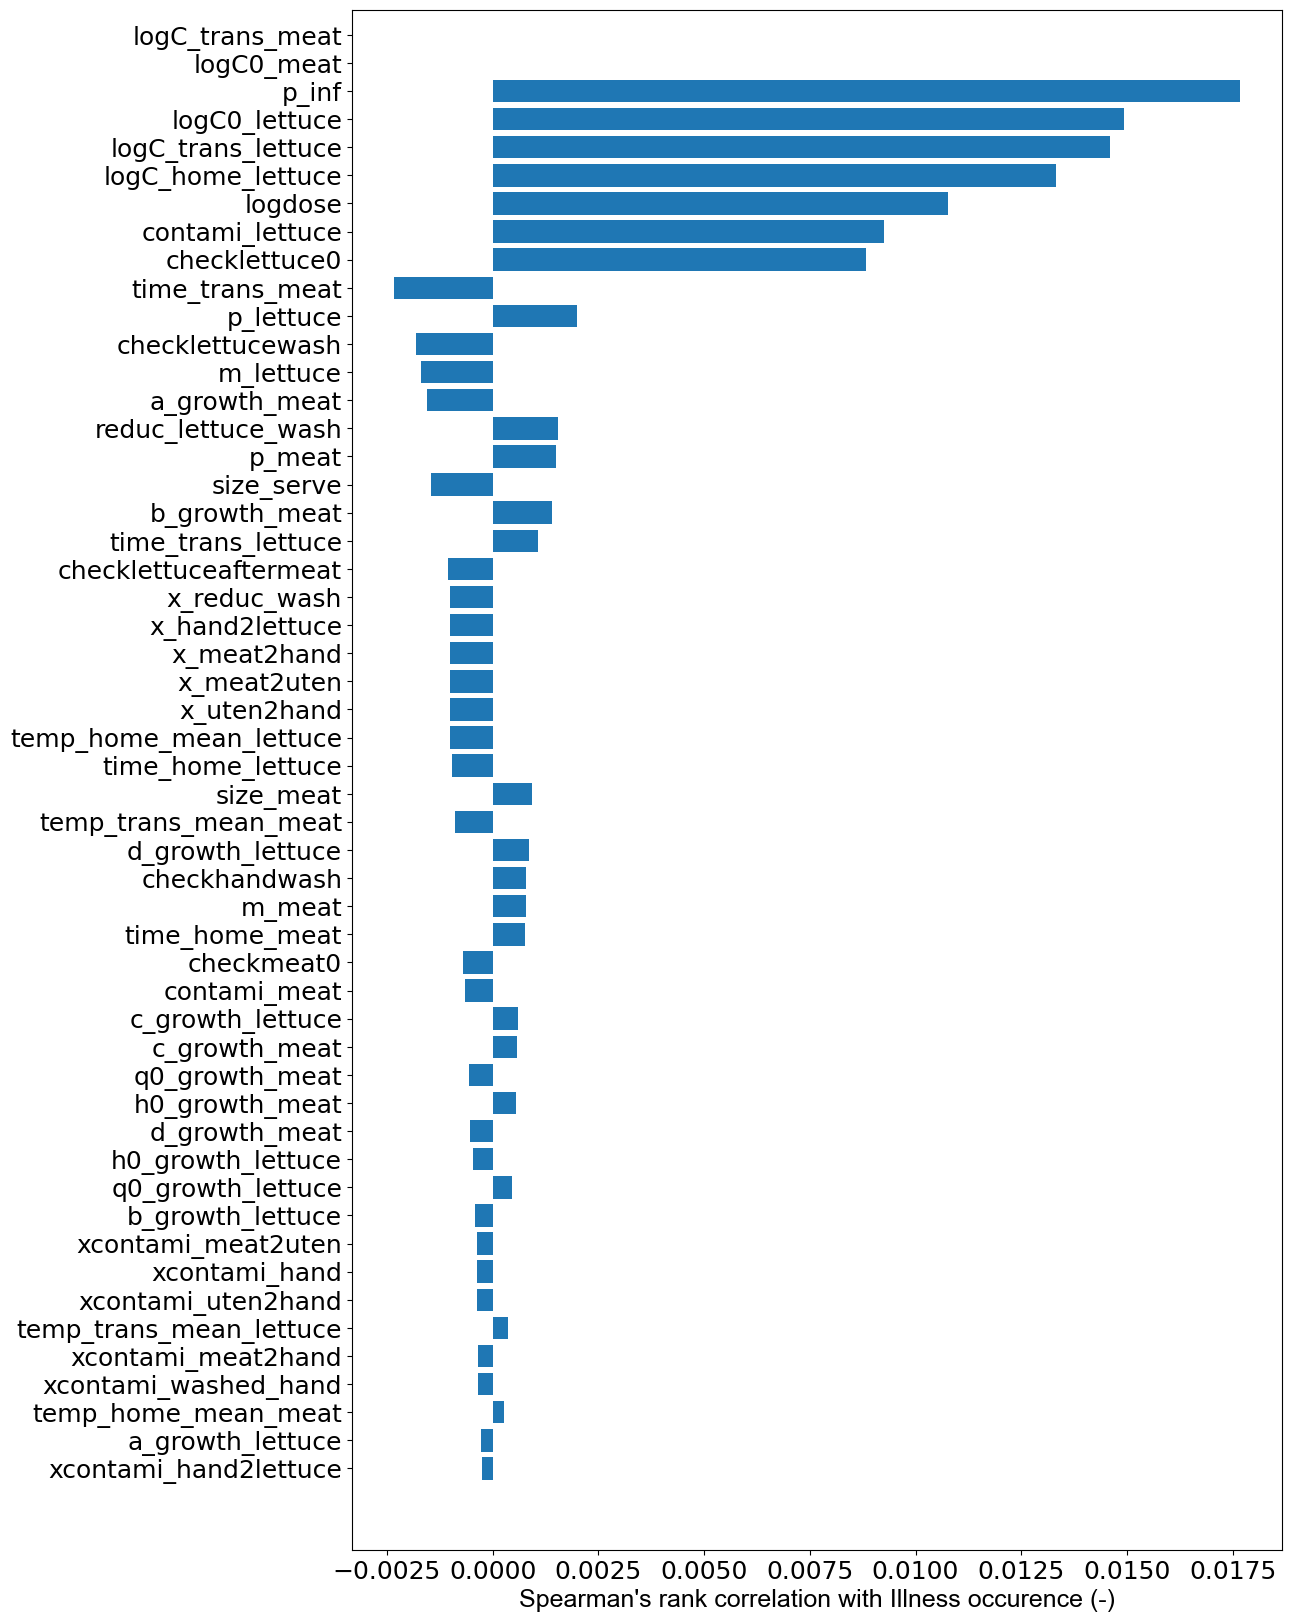

In [6]:
fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_corr.drop('checkInf', axis=0).index, 
        Sensitivity_corr.drop('checkInf', axis=0)["checkInf"])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with Illness occurence (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman.pdf", bbox_inches="tight", dpi=500)
plt.show()

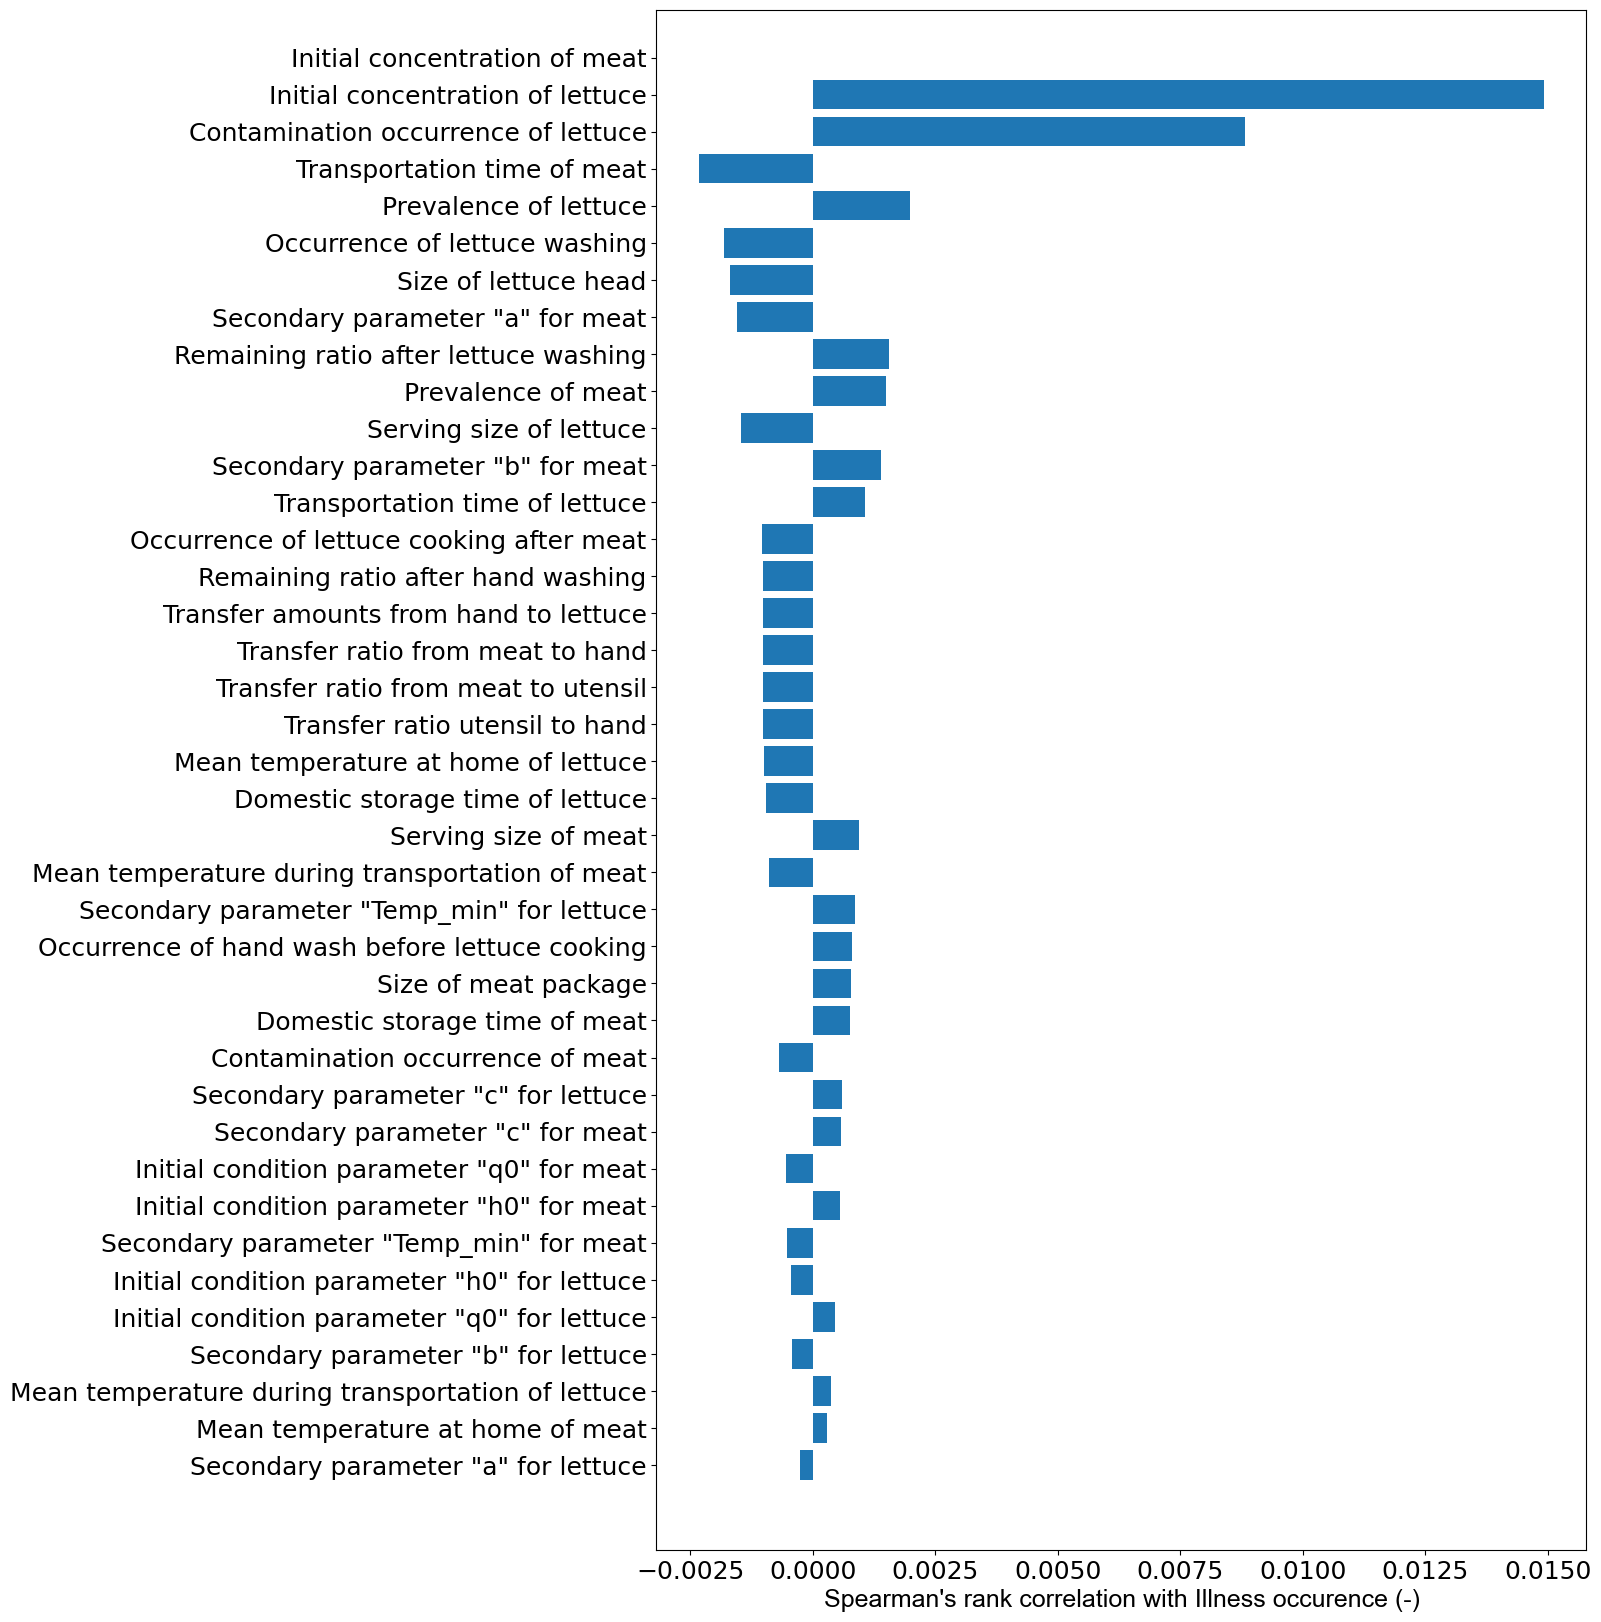

In [12]:
FactorColumns = ['m_lettuce', 'm_meat', 'p_lettuce', 'checklettuce0','logC0_lettuce', 'p_meat', 'checkmeat0', 
                 'logC0_meat','a_growth_lettuce', 'b_growth_lettuce', 'c_growth_lettuce','d_growth_lettuce', 
                 'h0_growth_lettuce', 'q0_growth_lettuce','a_growth_meat', 'b_growth_meat', 'c_growth_meat', 
                 'd_growth_meat','h0_growth_meat', 'q0_growth_meat', 'time_trans_lettuce', 'temp_trans_mean_lettuce','time_home_lettuce',
                 'temp_home_mean_lettuce','time_trans_meat', 
                 'temp_trans_mean_meat','time_home_meat',  
                 'temp_home_mean_meat', 'size_meat', 'checklettuceaftermeat', 'x_meat2uten', 'x_meat2hand','x_uten2hand', 'x_reduc_wash', 
                 'checkhandwash', 'checklettucewash', 'reduc_lettuce_wash', 'x_hand2lettuce','size_serve']
Sensitivity_factors_corr = Sensitivity_corr.loc[FactorColumns]
Sensitivity_factors_corr = Sensitivity_factors_corr.reindex(Sensitivity_factors_corr["checkInf"].abs().sort_values().index)


Sensitivity_factors_corr = Sensitivity_factors_corr.rename(index={
    'm_lettuce': 'Size of lettuce head',  
    'm_meat': 'Size of meat package',  
    'p_lettuce': 'Prevalence of lettuce',  
    'checklettuce0': 'Contamination occurrence of lettuce', 
    'logC0_lettuce': 'Initial concentration of lettuce', 
    'p_meat': 'Prevalence of meat', 
    'checkmeat0': 'Contamination occurrence of meat', 
    'logC0_meat': 'Initial concentration of meat', 
    'a_growth_lettuce': 'Secondary parameter "a" for lettuce', 
    'b_growth_lettuce': 'Secondary parameter "b" for lettuce', 
    'c_growth_lettuce': 'Secondary parameter "c" for lettuce', 
    'd_growth_lettuce': 'Secondary parameter "Temp_min" for lettuce',  
    'h0_growth_lettuce': 'Initial condition parameter "h0" for lettuce',  
    'q0_growth_lettuce': 'Initial condition parameter "q0" for lettuce', 
    'a_growth_meat': 'Secondary parameter "a" for meat',  
    'b_growth_meat': 'Secondary parameter "b" for meat',  
    'c_growth_meat': 'Secondary parameter "c" for meat',  
    'd_growth_meat': 'Secondary parameter "Temp_min" for meat', 
    'h0_growth_meat': 'Initial condition parameter "h0" for meat',  
    'q0_growth_meat': 'Initial condition parameter "q0" for meat',  
    'time_trans_lettuce': 'Transportation time of lettuce',  
    'temp_trans_mean_lettuce': 'Mean temperature during transportation of lettuce', 
    'time_home_lettuce': 'Domestic storage time of lettuce', 
    'temp_home_mean_lettuce': 'Mean temperature at home of lettuce', 
    'time_trans_meat': 'Transportation time of meat',  
    'temp_trans_mean_meat': 'Mean temperature during transportation of meat', 
    'time_home_meat': 'Domestic storage time of meat', 
    'temp_home_mean_meat': 'Mean temperature at home of meat', 
    'size_meat': 'Serving size of meat',  
    'checklettuceaftermeat': 'Occurrence of lettuce cooking after meat',  
    'x_meat2uten': 'Transfer ratio from meat to utensil',  
    'x_meat2hand': 'Transfer ratio from meat to hand', 
    'x_uten2hand': 'Transfer ratio utensil to hand',  
    'x_reduc_wash': 'Remaining ratio after hand washing',  
    'checkhandwash': 'Occurrence of hand wash before lettuce cooking',  
    'checklettucewash': 'Occurrence of lettuce washing',  
    'reduc_lettuce_wash': 'Remaining ratio after lettuce washing',  
    'x_hand2lettuce': 'Transfer amounts from hand to lettuce', 
    'size_serve': 'Serving size of lettuce'})

fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_factors_corr.index[0:len(Sensitivity_factors_corr["checkInf"])], 
        Sensitivity_factors_corr["checkInf"][0:len(Sensitivity_factors_corr["checkInf"])])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with Illness occurence (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman factors.pdf", bbox_inches="tight", dpi=500)
plt.show()

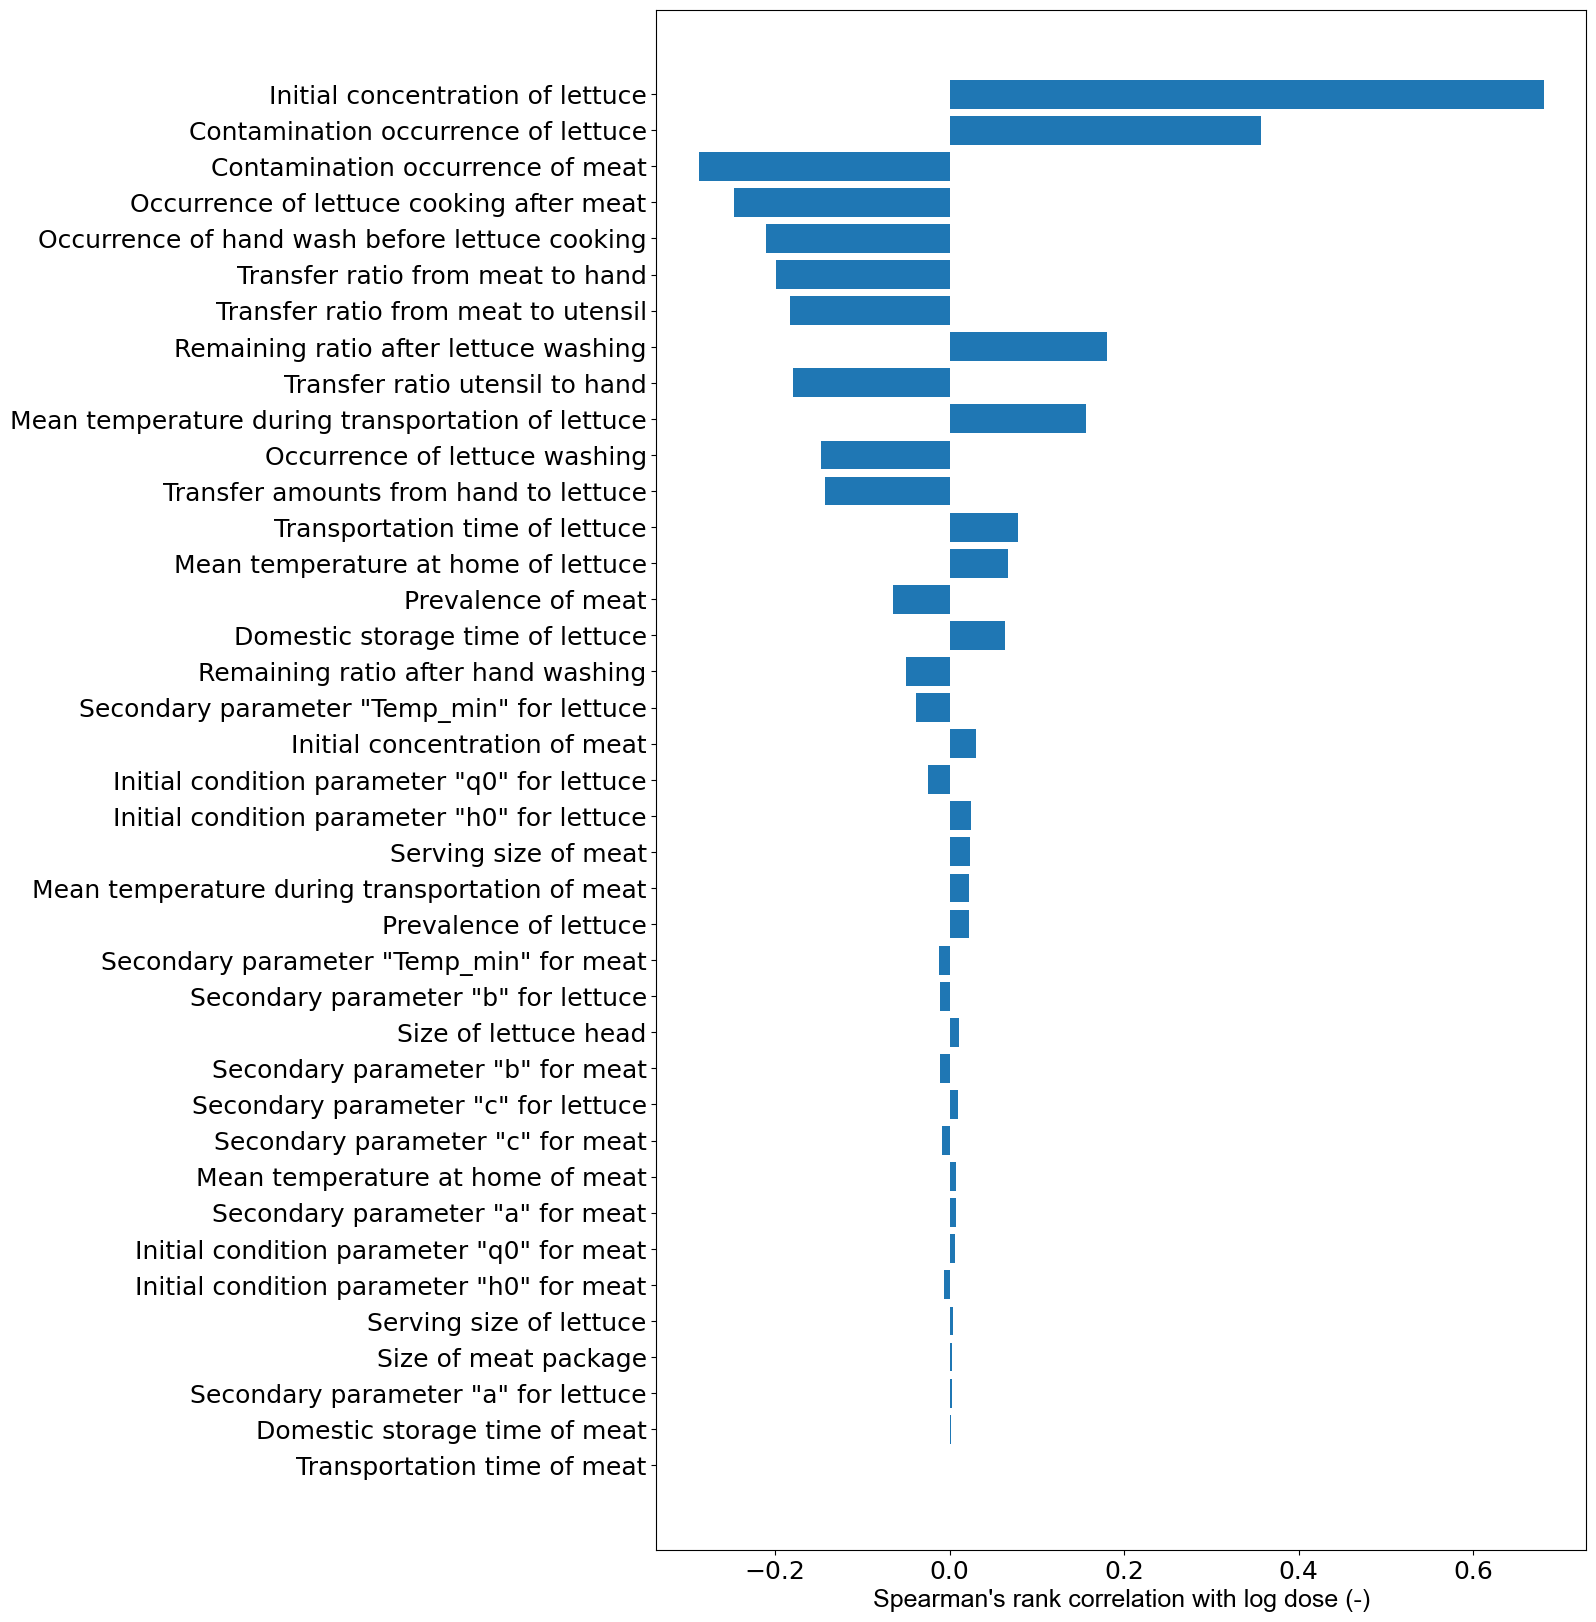

In [13]:
Sensitivity_corr_logdose = pd.read_csv("results/log dose Spearman.csv", index_col=0)
Sensitivity_corr_logdose = Sensitivity_corr_logdose.reindex(Sensitivity_corr_logdose["logdose"].abs().sort_values().index)

FactorColumns = ['m_lettuce', 'm_meat', 'p_lettuce', 'checklettuce0','logC0_lettuce', 'p_meat', 'checkmeat0', 
                 'logC0_meat','a_growth_lettuce', 'b_growth_lettuce', 'c_growth_lettuce','d_growth_lettuce', 
                 'h0_growth_lettuce', 'q0_growth_lettuce','a_growth_meat', 'b_growth_meat', 'c_growth_meat', 
                 'd_growth_meat','h0_growth_meat', 'q0_growth_meat', 'time_trans_lettuce', 'temp_trans_mean_lettuce','time_home_lettuce',
                 'temp_home_mean_lettuce','time_trans_meat', 
                 'temp_trans_mean_meat','time_home_meat',  
                 'temp_home_mean_meat', 'size_meat', 'checklettuceaftermeat', 'x_meat2uten', 'x_meat2hand','x_uten2hand', 'x_reduc_wash', 
                 'checkhandwash', 'checklettucewash', 'reduc_lettuce_wash', 'x_hand2lettuce','size_serve']
Sensitivity_factors_corr = Sensitivity_corr_logdose.loc[FactorColumns]
Sensitivity_factors_corr = Sensitivity_factors_corr.reindex(Sensitivity_factors_corr["logdose"].abs().sort_values().index)


Sensitivity_factors_corr = Sensitivity_factors_corr.rename(index={
    'm_lettuce': 'Size of lettuce head',  
    'm_meat': 'Size of meat package',  
    'p_lettuce': 'Prevalence of lettuce',  
    'checklettuce0': 'Contamination occurrence of lettuce', 
    'logC0_lettuce': 'Initial concentration of lettuce', 
    'p_meat': 'Prevalence of meat', 
    'checkmeat0': 'Contamination occurrence of meat', 
    'logC0_meat': 'Initial concentration of meat', 
    'a_growth_lettuce': 'Secondary parameter "a" for lettuce', 
    'b_growth_lettuce': 'Secondary parameter "b" for lettuce', 
    'c_growth_lettuce': 'Secondary parameter "c" for lettuce', 
    'd_growth_lettuce': 'Secondary parameter "Temp_min" for lettuce',  
    'h0_growth_lettuce': 'Initial condition parameter "h0" for lettuce',  
    'q0_growth_lettuce': 'Initial condition parameter "q0" for lettuce', 
    'a_growth_meat': 'Secondary parameter "a" for meat',  
    'b_growth_meat': 'Secondary parameter "b" for meat',  
    'c_growth_meat': 'Secondary parameter "c" for meat',  
    'd_growth_meat': 'Secondary parameter "Temp_min" for meat', 
    'h0_growth_meat': 'Initial condition parameter "h0" for meat',  
    'q0_growth_meat': 'Initial condition parameter "q0" for meat',  
    'time_trans_lettuce': 'Transportation time of lettuce',  
    'temp_trans_mean_lettuce': 'Mean temperature during transportation of lettuce', 
    'time_home_lettuce': 'Domestic storage time of lettuce', 
    'temp_home_mean_lettuce': 'Mean temperature at home of lettuce', 
    'time_trans_meat': 'Transportation time of meat',  
    'temp_trans_mean_meat': 'Mean temperature during transportation of meat', 
    'time_home_meat': 'Domestic storage time of meat', 
    'temp_home_mean_meat': 'Mean temperature at home of meat', 
    'size_meat': 'Serving size of meat',  
    'checklettuceaftermeat': 'Occurrence of lettuce cooking after meat',  
    'x_meat2uten': 'Transfer ratio from meat to utensil',  
    'x_meat2hand': 'Transfer ratio from meat to hand', 
    'x_uten2hand': 'Transfer ratio utensil to hand',  
    'x_reduc_wash': 'Remaining ratio after hand washing',  
    'checkhandwash': 'Occurrence of hand wash before lettuce cooking',  
    'checklettucewash': 'Occurrence of lettuce washing',  
    'reduc_lettuce_wash': 'Remaining ratio after lettuce washing',  
    'x_hand2lettuce': 'Transfer amounts from hand to lettuce', 
    'size_serve': 'Serving size of lettuce'})

fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_factors_corr.index[0:len(Sensitivity_factors_corr["logdose"])], 
        Sensitivity_factors_corr["logdose"][0:len(Sensitivity_factors_corr["logdose"])])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with log dose (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman log dose.pdf", bbox_inches="tight", dpi=500)
plt.show()

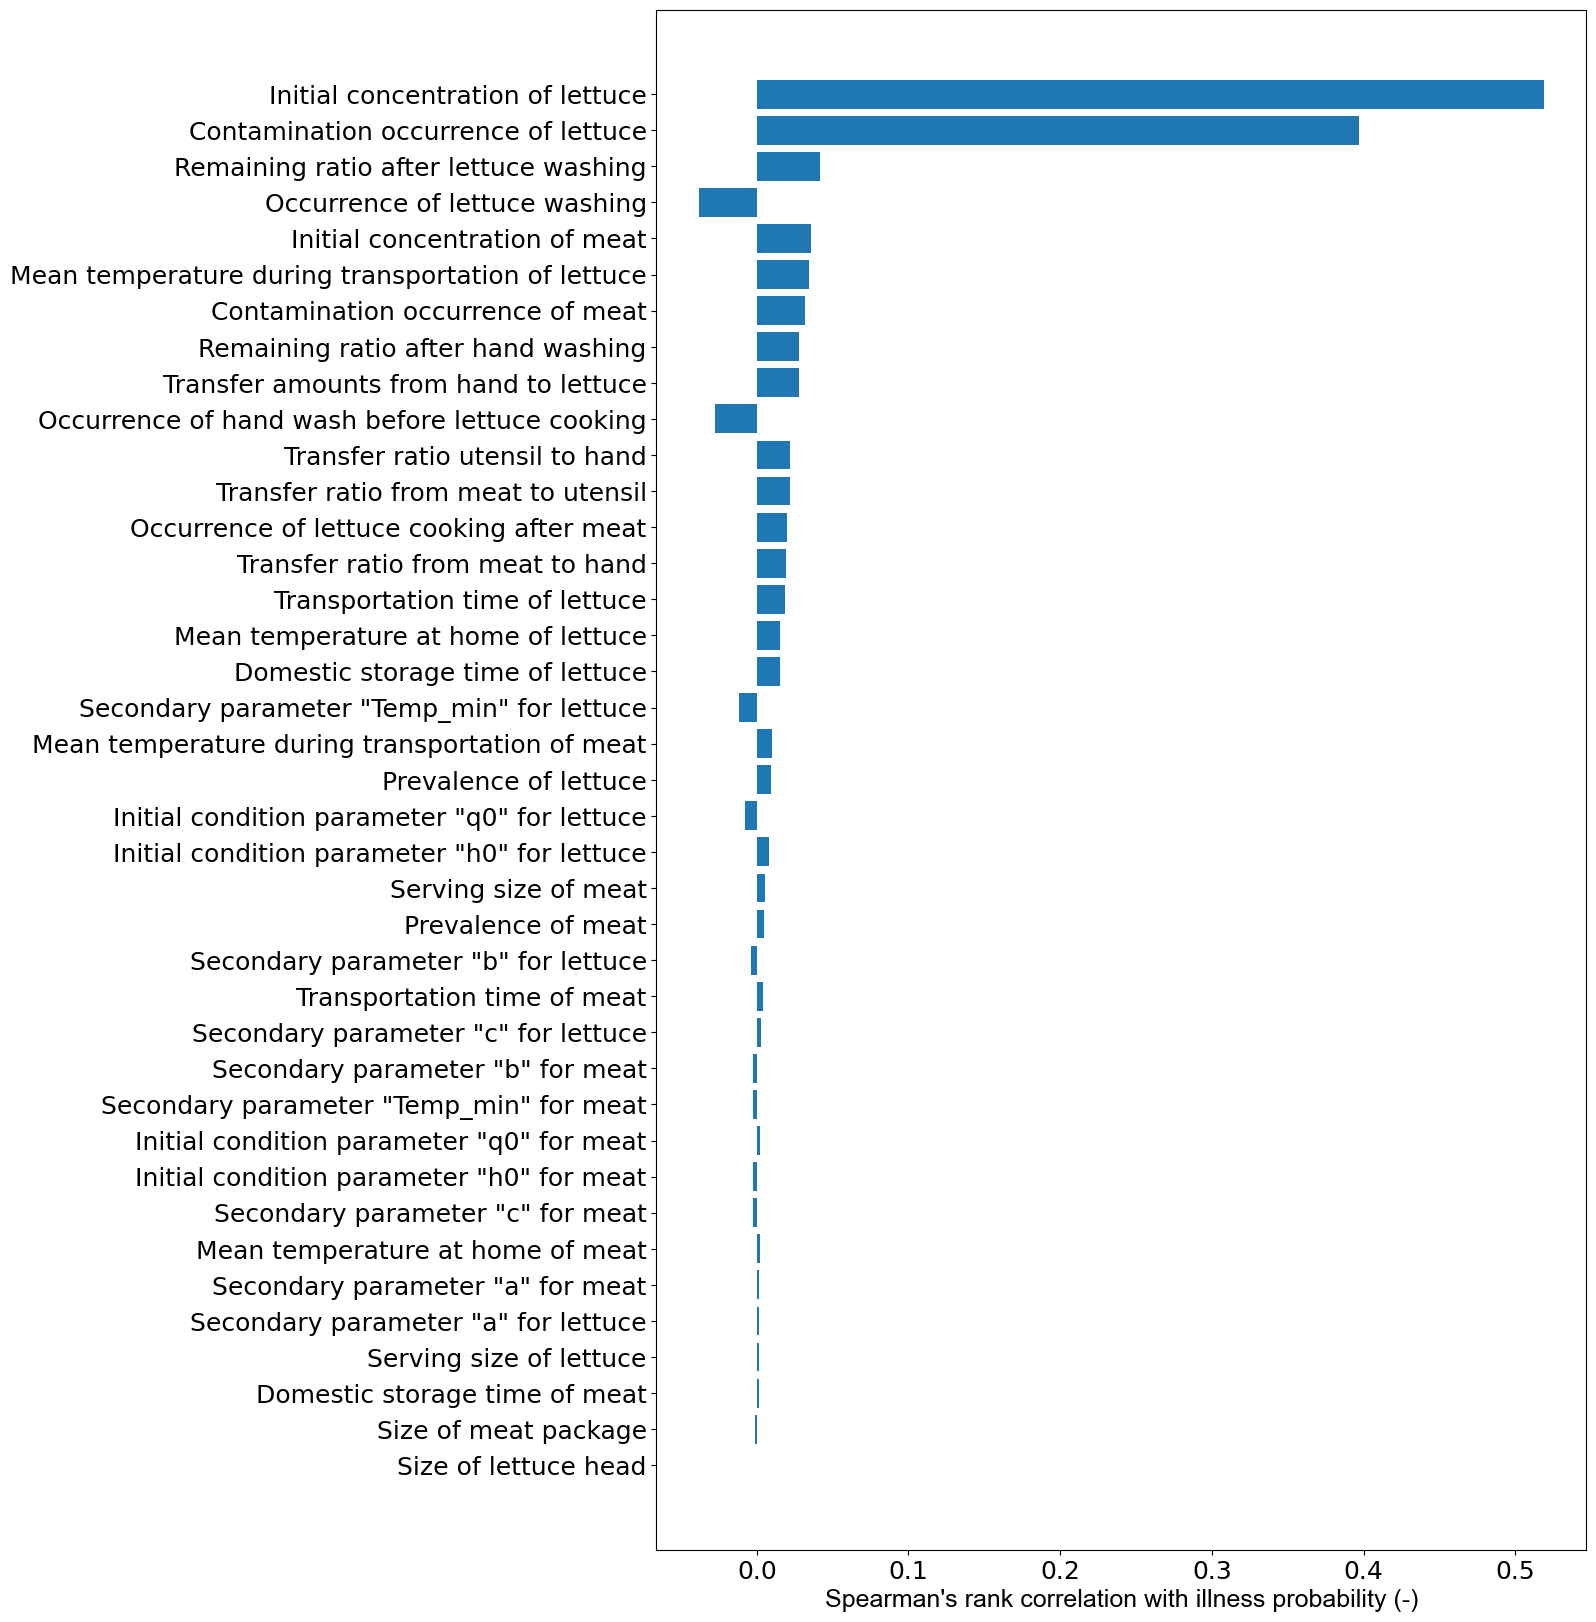

In [14]:
Sensitivity_corr_p_inf = pd.read_csv("results/p_inf Spearman.csv", index_col=0)
Sensitivity_corr_p_inf = Sensitivity_corr_p_inf.reindex(Sensitivity_corr_p_inf["p_inf"].abs().sort_values().index)

FactorColumns = ['m_lettuce', 'm_meat', 'p_lettuce', 'checklettuce0','logC0_lettuce', 'p_meat', 'checkmeat0', 
                 'logC0_meat','a_growth_lettuce', 'b_growth_lettuce', 'c_growth_lettuce','d_growth_lettuce', 
                 'h0_growth_lettuce', 'q0_growth_lettuce','a_growth_meat', 'b_growth_meat', 'c_growth_meat', 
                 'd_growth_meat','h0_growth_meat', 'q0_growth_meat', 'time_trans_lettuce', 'temp_trans_mean_lettuce','time_home_lettuce',
                 'temp_home_mean_lettuce','time_trans_meat', 
                 'temp_trans_mean_meat','time_home_meat',  
                 'temp_home_mean_meat', 'size_meat', 'checklettuceaftermeat', 'x_meat2uten', 'x_meat2hand','x_uten2hand', 'x_reduc_wash', 
                 'checkhandwash', 'checklettucewash', 'reduc_lettuce_wash', 'x_hand2lettuce','size_serve']
Sensitivity_factors_corr = Sensitivity_corr_p_inf.loc[FactorColumns]
Sensitivity_factors_corr = Sensitivity_factors_corr.reindex(Sensitivity_factors_corr["p_inf"].abs().sort_values().index)


Sensitivity_factors_corr = Sensitivity_factors_corr.rename(index={
    'm_lettuce': 'Size of lettuce head',  
    'm_meat': 'Size of meat package',  
    'p_lettuce': 'Prevalence of lettuce',  
    'checklettuce0': 'Contamination occurrence of lettuce', 
    'logC0_lettuce': 'Initial concentration of lettuce', 
    'p_meat': 'Prevalence of meat', 
    'checkmeat0': 'Contamination occurrence of meat', 
    'logC0_meat': 'Initial concentration of meat', 
    'a_growth_lettuce': 'Secondary parameter "a" for lettuce', 
    'b_growth_lettuce': 'Secondary parameter "b" for lettuce', 
    'c_growth_lettuce': 'Secondary parameter "c" for lettuce', 
    'd_growth_lettuce': 'Secondary parameter "Temp_min" for lettuce',  
    'h0_growth_lettuce': 'Initial condition parameter "h0" for lettuce',  
    'q0_growth_lettuce': 'Initial condition parameter "q0" for lettuce', 
    'a_growth_meat': 'Secondary parameter "a" for meat',  
    'b_growth_meat': 'Secondary parameter "b" for meat',  
    'c_growth_meat': 'Secondary parameter "c" for meat',  
    'd_growth_meat': 'Secondary parameter "Temp_min" for meat', 
    'h0_growth_meat': 'Initial condition parameter "h0" for meat',  
    'q0_growth_meat': 'Initial condition parameter "q0" for meat',  
    'time_trans_lettuce': 'Transportation time of lettuce',  
    'temp_trans_mean_lettuce': 'Mean temperature during transportation of lettuce', 
    'time_home_lettuce': 'Domestic storage time of lettuce', 
    'temp_home_mean_lettuce': 'Mean temperature at home of lettuce', 
    'time_trans_meat': 'Transportation time of meat',  
    'temp_trans_mean_meat': 'Mean temperature during transportation of meat', 
    'time_home_meat': 'Domestic storage time of meat', 
    'temp_home_mean_meat': 'Mean temperature at home of meat', 
    'size_meat': 'Serving size of meat',  
    'checklettuceaftermeat': 'Occurrence of lettuce cooking after meat',  
    'x_meat2uten': 'Transfer ratio from meat to utensil',  
    'x_meat2hand': 'Transfer ratio from meat to hand', 
    'x_uten2hand': 'Transfer ratio utensil to hand',  
    'x_reduc_wash': 'Remaining ratio after hand washing',  
    'checkhandwash': 'Occurrence of hand wash before lettuce cooking',  
    'checklettucewash': 'Occurrence of lettuce washing',  
    'reduc_lettuce_wash': 'Remaining ratio after lettuce washing',  
    'x_hand2lettuce': 'Transfer amounts from hand to lettuce', 
    'size_serve': 'Serving size of lettuce'})

fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_factors_corr.index[0:len(Sensitivity_factors_corr["p_inf"])], 
        Sensitivity_factors_corr["p_inf"][0:len(Sensitivity_factors_corr["p_inf"])])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with illness probability (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman illness probability.pdf", bbox_inches="tight", dpi=500)
plt.show()

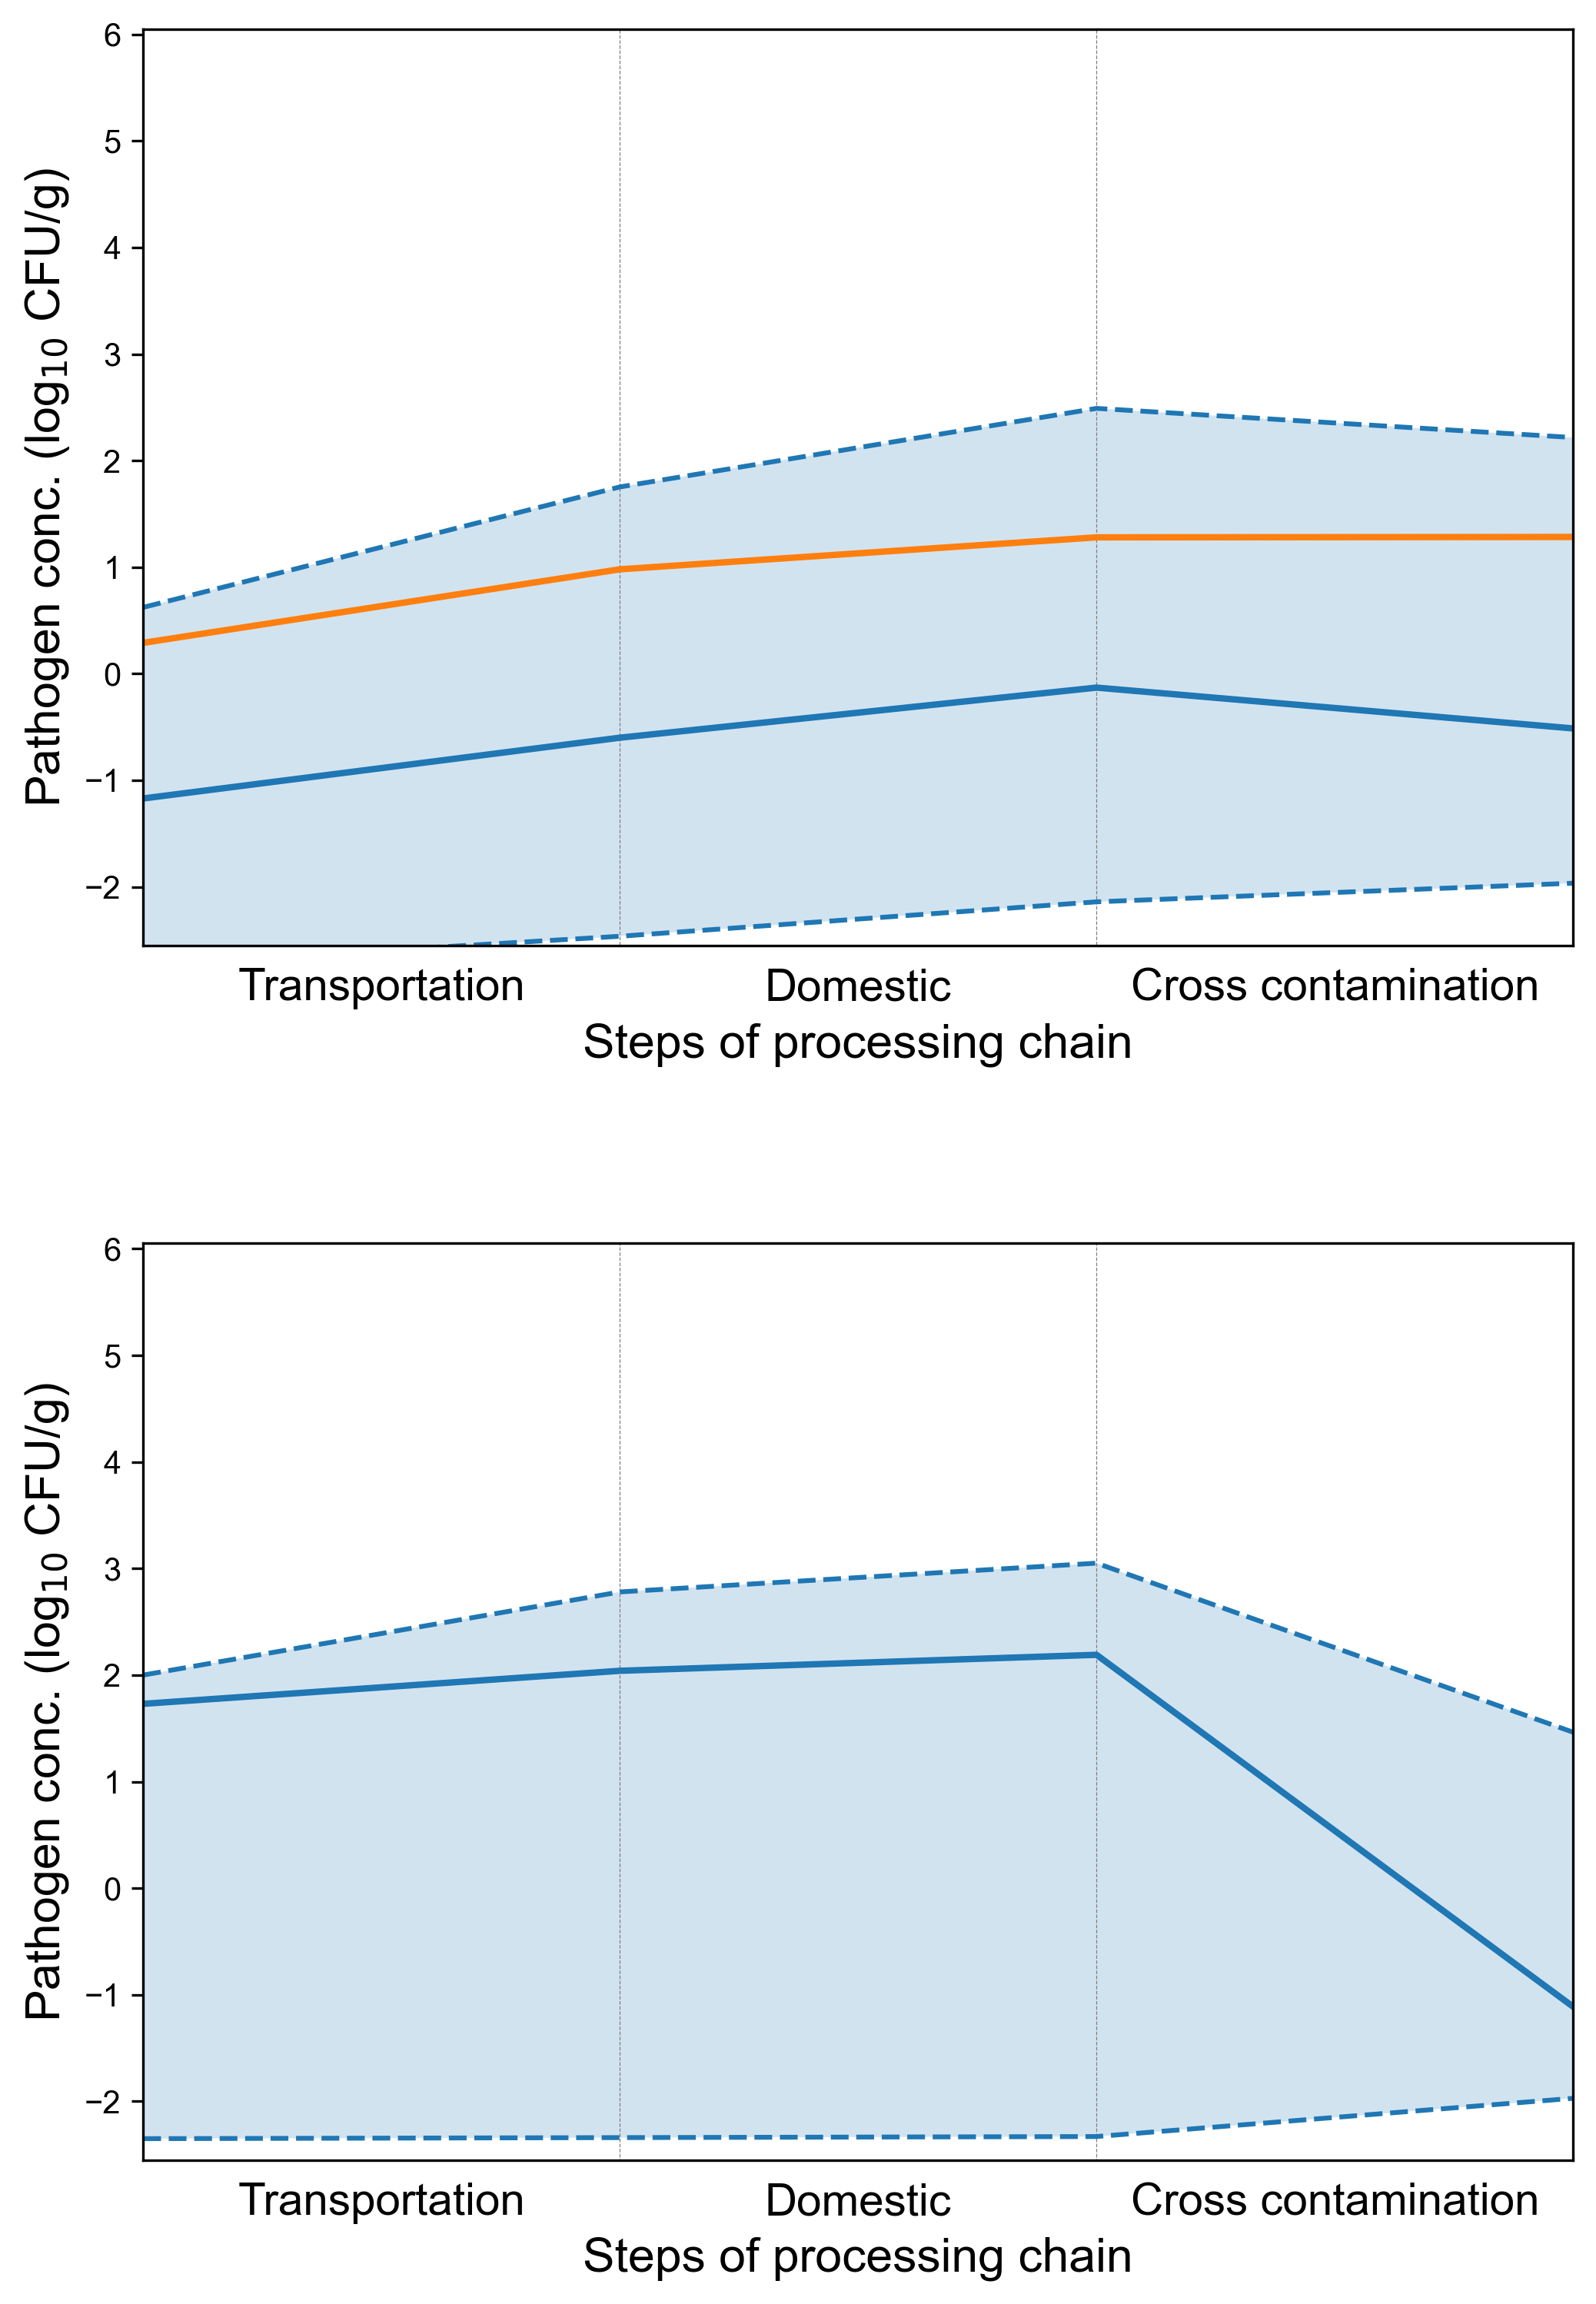

In [11]:
Palette=sns.color_palette(n_colors = 4)
logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC0_lettuce"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_trans_lettuce"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_home_lettuce"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["size_serve"])


logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))



fig, ax = plt.subplots(2, 1, gridspec_kw={'width_ratios': [1], 'height_ratios': [1, 1]},figsize=(8,12), dpi=300)
plt.subplots_adjust(wspace=0, hspace=0.325)
plt.rcParams["font.family"] = "Arial"


ax[0].set_xticks([0.5, 1.5, 2.5])
ax[0].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[0].tick_params(bottom=False)
ax[0].set_ylim([-2.55, 6.05])
ax[0].set_xlim([-0, 3])



ax[0].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[0].set_ylabel("Pathogen conc. (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[0].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[0].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)
ax[0].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)

#ax[0].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)

#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)].index:
#        ax[0].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)


ax[0].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')


ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')



logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logC0_meat"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC0_meat"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_trans_meat"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_home_meat"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["size_serve"])

ax[1].set_xticks([0.5, 1.5, 2.5])
ax[1].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[1].tick_params(bottom=False)
ax[1].set_ylim([-2.55, 6.05])
ax[1].set_xlim([-0, 3])



ax[1].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[1].set_ylabel("Pathogen conc. (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[1].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[1].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)

if len(logC0_ill) < 3:
    if len(logC0_ill) != 0:
        logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
        logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
        logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
        logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))


        ax[1].fill_between([0,1,2,3], 
                           [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                           alpha=0.2)

        ax[1].plot([0,1,2,3], 
                   [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
        ax[1].plot([0,1,2,3], 
                   [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
        ax[1].plot([0,1,2,3], 
                   [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')

        
#ax[1].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)


#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)].index:
#        ax[1].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)

ax[1].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[1].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[1].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')





plt.savefig("plot/Step and conc.pdf", bbox_inches="tight", dpi=500)
plt.show()

In [18]:
[logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]]

[0.29, 0.98, 1.28, 1.28344948089855]

In [19]:
len(logC0_ill)

0

In [12]:
np.min(Sim_results["logC0_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logC0_meat"]!=-np.inf)])

-2.39

In [16]:
np.sum(Sim_results["logC0_meat"]==-np.inf)

427670

In [17]:
np.sum(Sim_results["checkmeat0"]==0)

420529

In [8]:
 logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]

(nan, nan, -1.9711215441664067)

In [38]:
Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC0_meat"]

Series([], Name: logC0_meat, dtype: float64)

In [39]:
ax[1].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)


In [40]:
np.sum(Sim_results["checkInf"])

1

In [41]:
Sim_results["logC_home_lettuce"][Sim_results["checklettuce0"]==1]

26       -1.35
67       -1.88
138      -0.84
170      -1.05
206       0.02
          ... 
528197   -1.46
528209    0.00
528217   -0.68
528273    0.67
528288   -0.19
Name: logC_home_lettuce, Length: 12534, dtype: float64

In [42]:
Sim_results["logC_home_meat"][Sim_results["checkmeat0"]==1]

5         2.32
6         -inf
17        -inf
23        2.17
24        2.05
          ... 
528383    -inf
528391    2.85
528392    -inf
528393    2.67
528399    2.69
Name: logC_home_meat, Length: 107871, dtype: float64

In [43]:
Sim_results["logdose"][Sim_results["logdose"]!=0]

0        -inf
1        -inf
2        -inf
3        -inf
4        -inf
         ... 
528395   -inf
528396   -inf
528397   -inf
528398   -inf
528399   -inf
Name: logdose, Length: 524411, dtype: float64

In [44]:
np.sum(Sim_results ["checkmeat0"])

107871

In [45]:
np.sum(Sim_results["checkInf"])

1

In [46]:
Sim_results[Sim_results["checkInf"]==1]["checkmeat0"]

375518    0
Name: checkmeat0, dtype: int64

In [47]:
Sim_results[Sim_results["checkInf"]==1]["checklettuce0"]

375518    1
Name: checklettuce0, dtype: int64

In [48]:
Sim_results[Sim_results["checkInf"]==1]["checkhandwash"]

375518    1
Name: checkhandwash, dtype: int64

In [49]:

Testtemp_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_lettuce"]!=-np.inf)].reset_index()["temp_trans_lettuce"]
TestlogC_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_lettuce"]!=-np.inf)].reset_index()["logCs_trans_lettuce"]
Testts_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_lettuce"]!=-np.inf)].reset_index()["ts_trans_lettuce"]
Testts = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)].reset_index()["ts_trans_meat"]
Testtemp = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)].reset_index()["temp_trans_meat"]
TestlogC = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_trans_meat"]!=-np.inf)].reset_index()["logCs_trans_meat"]


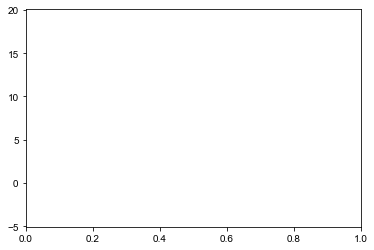

In [50]:
for i in Testts.index:
    plt.plot(Testts[i], Testtemp[i])
plt.ylim([-5.05, 20.05])
plt.show()

In [51]:
for i in Testts.index:
    plt.plot(Testts[i], TestlogC[i])
plt.show()

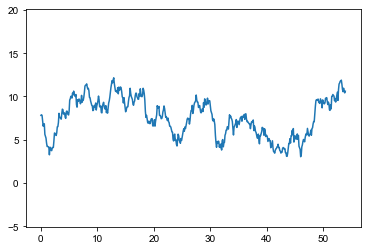

In [52]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], Testtemp_lettuce[i])
plt.ylim([-5.05, 20.05])
plt.show()

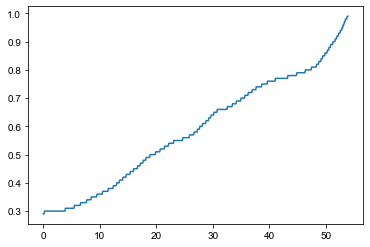

In [53]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], TestlogC_lettuce[i])
plt.show()

In [54]:

Testtemp_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_lettuce"]!=-np.inf)].reset_index()["temp_home_lettuce"]
TestlogC_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_lettuce"]!=-np.inf)].reset_index()["logCs_home_lettuce"]
Testts_lettuce = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_lettuce"]!=-np.inf)].reset_index()["ts_home_lettuce"]
Testts = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)].reset_index()["ts_home_meat"]
Testtemp = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)].reset_index()["temp_home_meat"]
TestlogC = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-np.inf)].reset_index()["logCs_home_meat"]


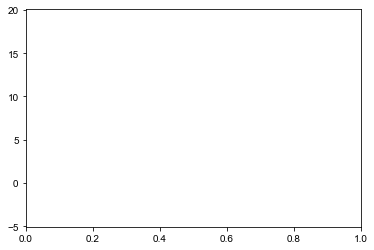

In [55]:
for i in Testts.index:
    plt.plot(Testts[i], Testtemp[i])
plt.ylim([-5.05, 20.05])
plt.show()

In [56]:
for i in Testts.index:
    plt.plot(Testts[i], TestlogC[i])
plt.show()

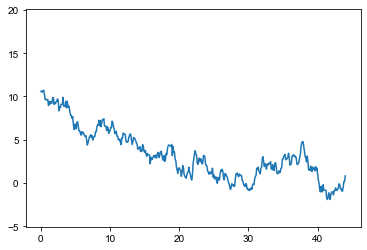

In [57]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], Testtemp_lettuce[i])
plt.ylim([-5.05, 20.05])
plt.show()

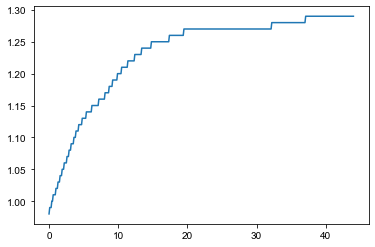

In [58]:
for i in Testtemp_lettuce.index:
    plt.plot(Testts_lettuce[i], TestlogC_lettuce[i])
plt.show()

In [59]:
np.sum(Sim_results ["checkInf"])

1

(array([ 4019.,  6483.,  4865.,  2457.,  2185.,  2182.,  5189., 59038.,
        14102.,   210.]),
 array([-2.39 , -1.774, -1.158, -0.542,  0.074,  0.69 ,  1.306,  1.922,
         2.538,  3.154,  3.77 ]),
 <BarContainer object of 10 artists>)

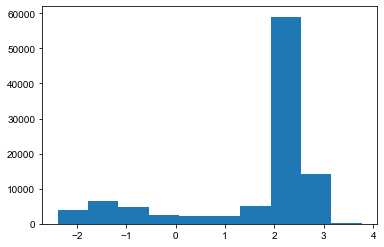

In [60]:
plt.hist(Sim_results ["logC_home_meat"][Sim_results ["logC_home_meat"]!=-np.inf])

(array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]),
 array([2.69, 2.79, 2.89, 2.99, 3.09, 3.19, 3.29, 3.39, 3.49, 3.59, 3.69]),
 <BarContainer object of 10 artists>)

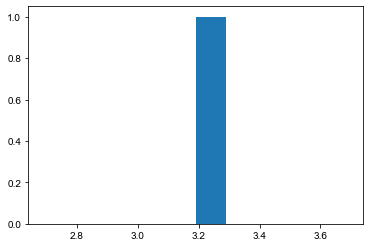

In [61]:
plt.hist(Sim_results["logdose"][Sim_results["checkInf"]==1])

(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

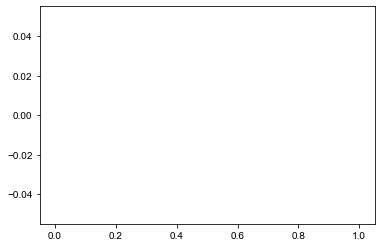

In [62]:
plt.hist(Sim_results["logC_home_meat"][(Sim_results["checkInf"]==1)&(Sim_results["logC_home_meat"]!=-float('inf'))])

In [63]:
#病気の中のレタス有病率
np.sum(Sim_results["checklettuce0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

1.0

In [64]:
#感染の中の肉有病率
np.sum(Sim_results["checkmeat0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.0

In [65]:
#感染の中の生肉を先に調理している確率
np.sum(Sim_results["checklettuceaftermeat"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.0

In [66]:
#感染の中のレタスを洗っている割合
np.sum(Sim_results["checklettucewash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.0

In [67]:
#感染の中の手洗いしていない率
1-np.sum(Sim_results["checkhandwash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.0

(array([ 288.,  899., 2202., 3101., 2823., 1793.,  824.,  237.,   53.,
           9.]),
 array([-2.79 , -2.133, -1.476, -0.819, -0.162,  0.495,  1.152,  1.809,
         2.466,  3.123,  3.78 ]),
 <BarContainer object of 10 artists>)

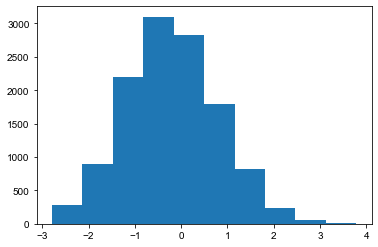

In [68]:
plt.hist(Sim_results ["logC_home_lettuce"][Sim_results ["logC_home_lettuce"]!=-np.inf])

(array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]),
 array([0.78, 0.88, 0.98, 1.08, 1.18, 1.28, 1.38, 1.48, 1.58, 1.68, 1.78]),
 <BarContainer object of 10 artists>)

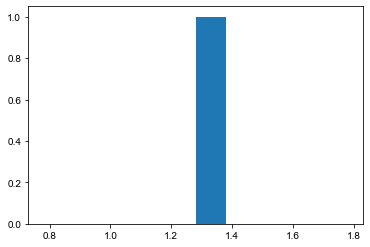

In [69]:
plt.hist(Sim_results ["logC_home_lettuce"][(Sim_results ["checkInf"]!=0)&(Sim_results["logC_home_lettuce"]!=-float('inf'))])

In [70]:
np.sum(Sim_results["checkInf"])

1

/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:905: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


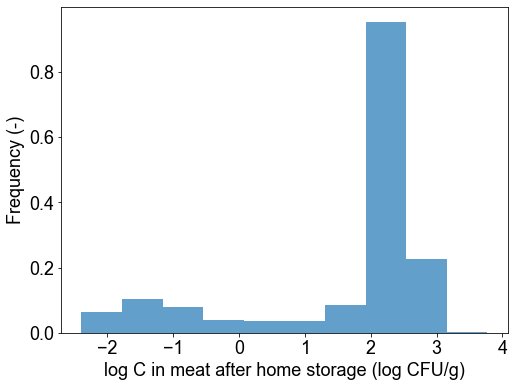

In [71]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC_home_meat"][Sim_results["logC_home_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC_home_meat"][Sim_results_ill["logC_home_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log C in meat after home storage (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log C in meat after home storage.pdf", bbox_inches="tight", dpi=500)

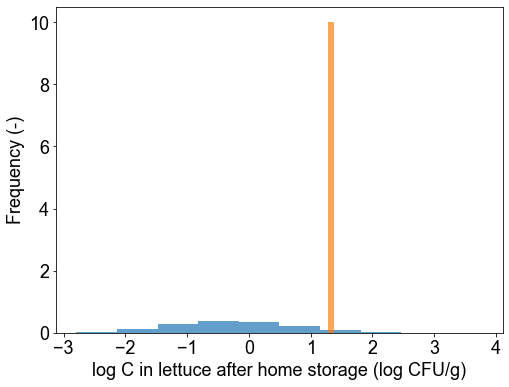

In [72]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC_home_lettuce"][Sim_results["logC_home_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC_home_lettuce"][Sim_results_ill["logC_home_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log C in lettuce after home storage (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log C in lettuce after home storage.pdf", bbox_inches="tight", dpi=500)

/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:905: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


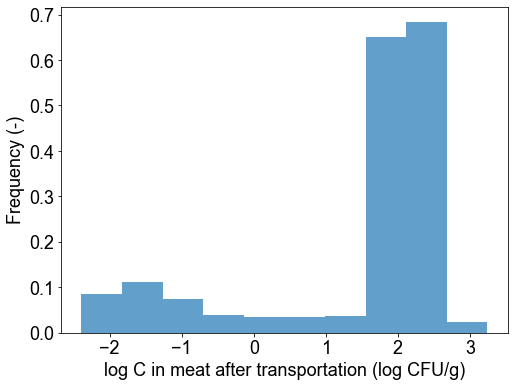

In [73]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC_trans_meat"][Sim_results["logC_trans_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC_trans_meat"][Sim_results_ill["logC_trans_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log C in meat after transportation (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log C in meat after transportation.pdf", bbox_inches="tight", dpi=500)

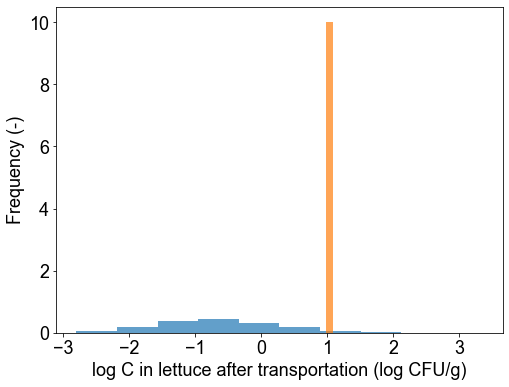

In [74]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC_trans_lettuce"][Sim_results["logC_trans_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC_trans_lettuce"][Sim_results_ill["logC_trans_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log C in lettuce after transportation (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log C in lettuce after transportation.pdf", bbox_inches="tight", dpi=500)

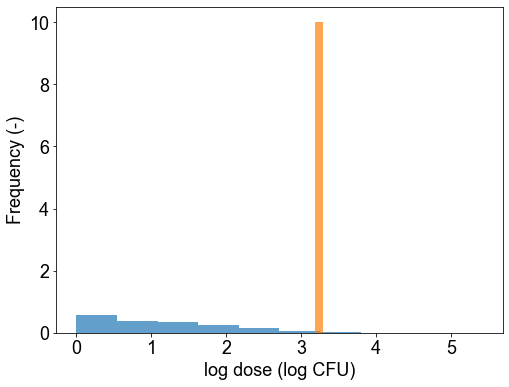

In [75]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logdose"][Sim_results["logdose"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logdose"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log dose.pdf", bbox_inches="tight", dpi=500)

In [6]:
np.max(Sim_results["logdose"])

5.42

In [8]:
bin_list = [i*0.25 for i in range(23)] 

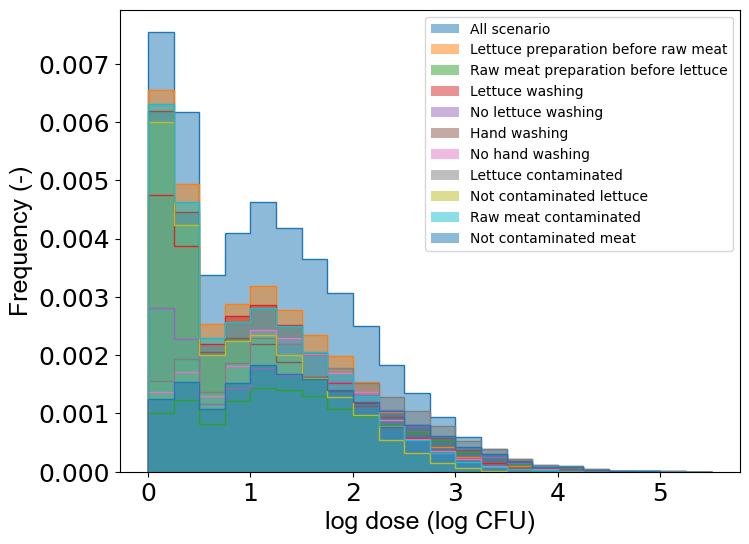

In [10]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce preparation before raw meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat preparation before lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose scenarios.pdf", bbox_inches="tight", dpi=500)

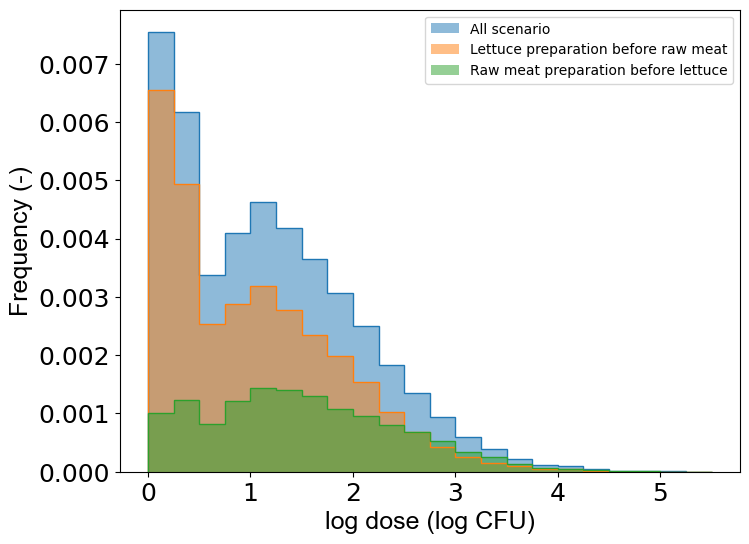

In [11]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce preparation before raw meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat preparation before lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose preparation sequence.pdf", bbox_inches="tight", dpi=500)

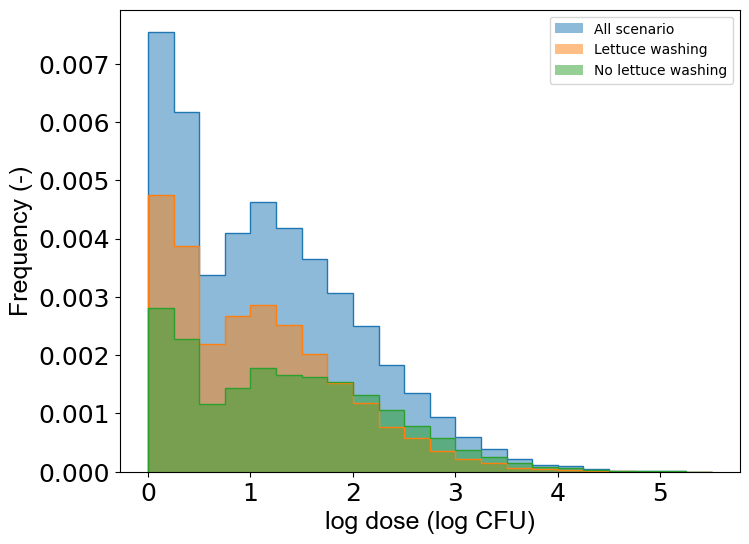

In [12]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose lettuce wash.pdf", bbox_inches="tight", dpi=500)

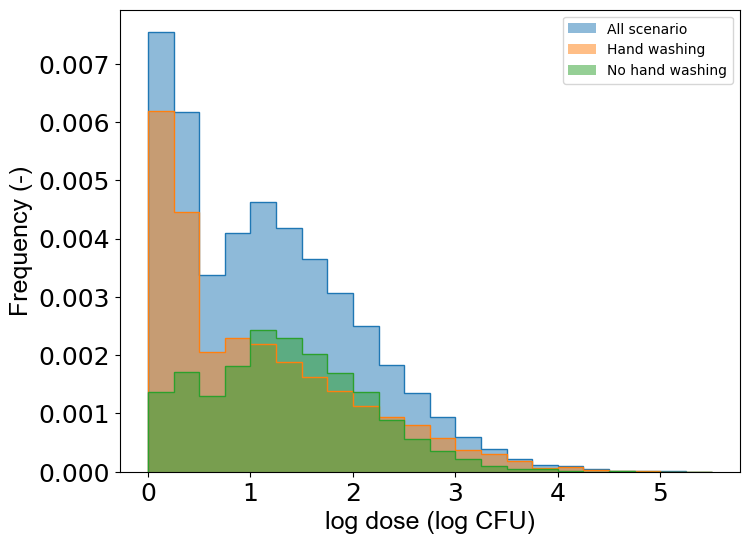

In [13]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose hand wash.pdf", bbox_inches="tight", dpi=500)

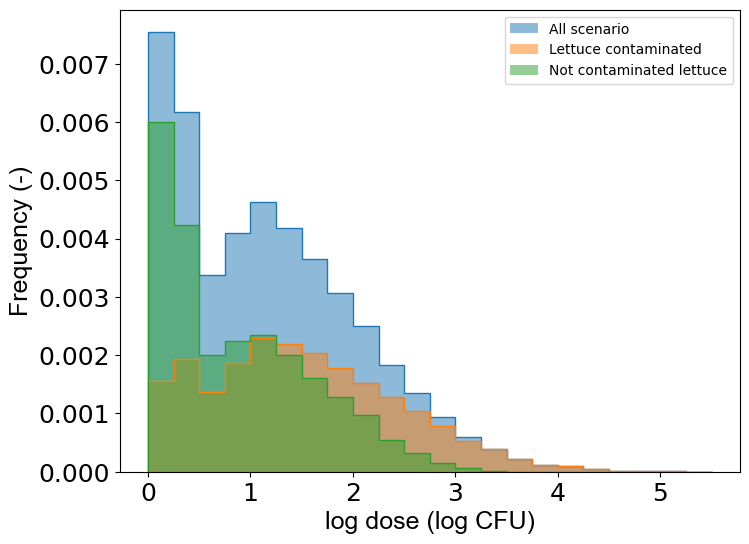

In [14]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose lettuce contamination.pdf", bbox_inches="tight", dpi=500)

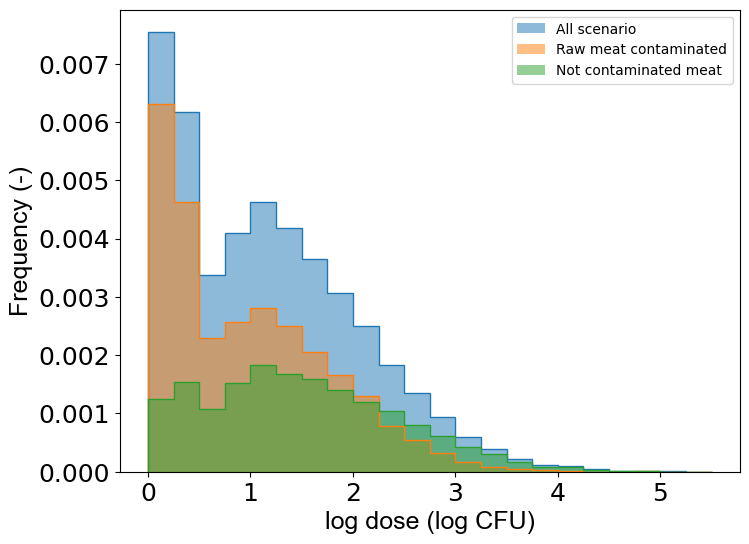

In [15]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose meat contamination.pdf", bbox_inches="tight", dpi=500)

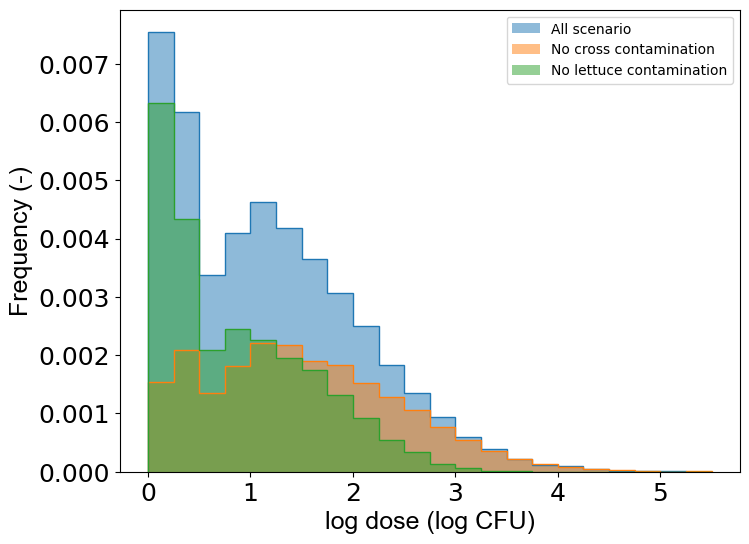

In [16]:
Sim_results_no_cross = pickle.load(open('results/Simulation results of repsim no cross.pkl', 'rb'))
Sim_results_no_lettuce = pickle.load(open('results/Simulation results of repsim no lettuce.pkl', 'rb'))

Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results_no_cross["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results_no_cross["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No cross contamination")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results_no_lettuce["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results_no_lettuce["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No lettuce contamination")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose Table 4.pdf", bbox_inches="tight", dpi=500)

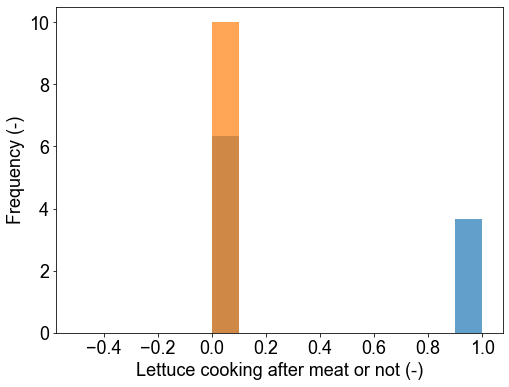

In [76]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checklettuceaftermeat"][Sim_results["checklettuceaftermeat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checklettuceaftermeat"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Lettuce cooking after meat or not (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Lettuce cooking after meat or not.pdf", bbox_inches="tight", dpi=500)

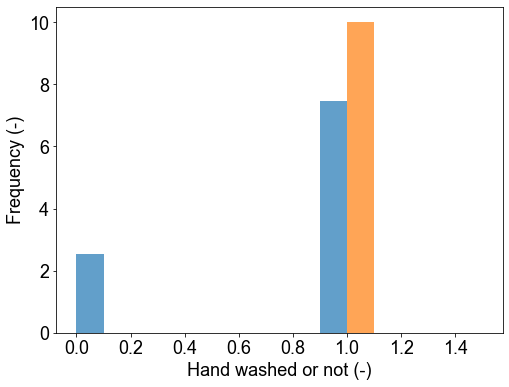

In [77]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checkhandwash"][Sim_results["checkhandwash"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checkhandwash"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Hand washed or not (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Hand washed or not.pdf", bbox_inches="tight", dpi=500)

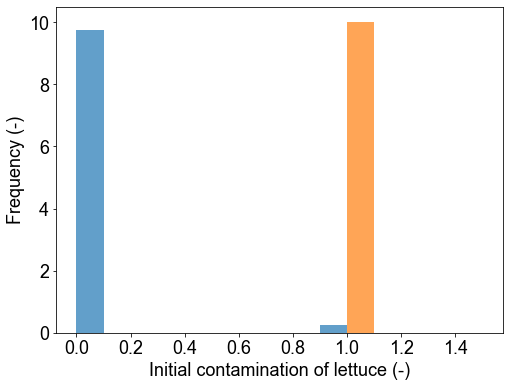

In [78]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checklettuce0"][Sim_results["checklettuce0"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checklettuce0"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of lettuce (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of lettuce.pdf", bbox_inches="tight", dpi=500)

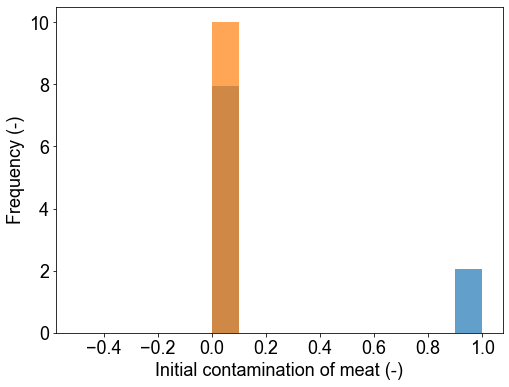

In [79]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checkmeat0"][Sim_results["checkmeat0"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checkmeat0"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of meat (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of meat.pdf", bbox_inches="tight", dpi=500)

(array([ 0.,  0.,  0.,  0., 10.,  0.,  0.,  0.,  0.,  0.]),
 array([-4.995e-01, -3.995e-01, -2.995e-01, -1.995e-01, -9.950e-02,
         5.000e-04,  1.005e-01,  2.005e-01,  3.005e-01,  4.005e-01,
         5.005e-01]),
 <BarContainer object of 10 artists>)

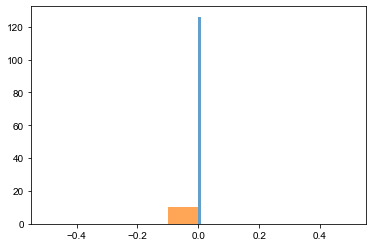

In [80]:
plt.hist(Sim_results["p_inf"][Sim_results["p_inf"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["p_inf"],density=True, alpha =0.7)

/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:905: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


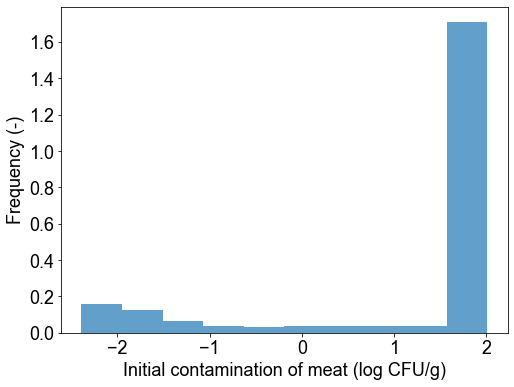

In [81]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC0_meat"][Sim_results["logC0_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC0_meat"][Sim_results["logC0_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of meat (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of meat.pdf", bbox_inches="tight", dpi=500)

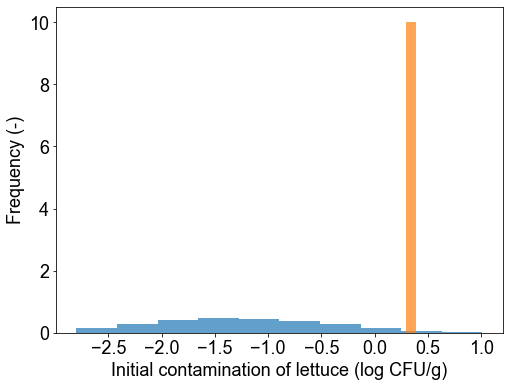

In [82]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC0_lettuce"][Sim_results["logC0_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC0_lettuce"][Sim_results["logC0_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of lettuce (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of lettuce.pdf", bbox_inches="tight", dpi=500)

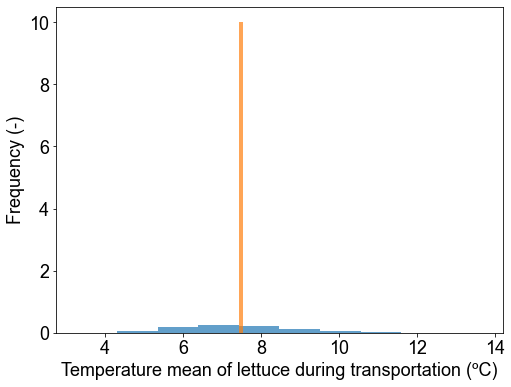

In [83]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["temp_trans_mean_lettuce"][Sim_results["temp_trans_mean_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["temp_trans_mean_lettuce"][Sim_results["temp_trans_mean_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Temperature mean of lettuce during transportation (ºC)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Temperature mean of lettuce during transportation.pdf", bbox_inches="tight", dpi=500)

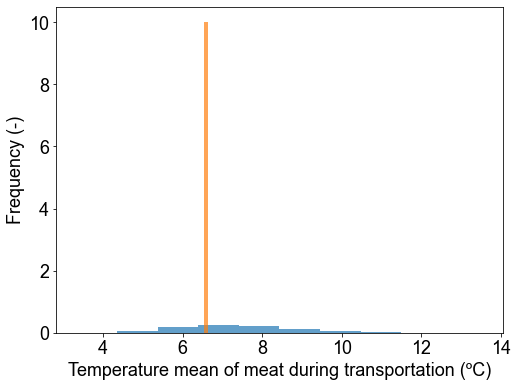

In [84]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["temp_trans_mean_meat"][Sim_results["temp_trans_mean_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["temp_trans_mean_meat"][Sim_results["temp_trans_mean_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Temperature mean of meat during transportation (ºC)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Temperature mean of meat during transportation.pdf", bbox_inches="tight", dpi=500)

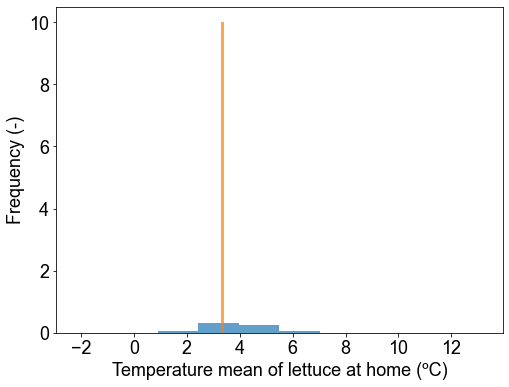

In [85]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["temp_home_mean_lettuce"][Sim_results["temp_home_mean_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["temp_home_mean_lettuce"][Sim_results["temp_home_mean_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Temperature mean of lettuce at home (ºC)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Temperature mean of lettuce at home.pdf", bbox_inches="tight", dpi=500)

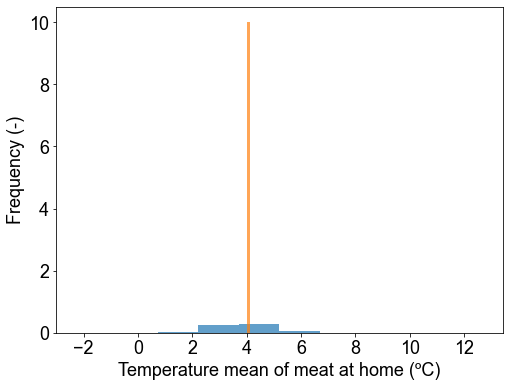

In [86]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["temp_home_mean_meat"][Sim_results["temp_home_mean_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["temp_home_mean_meat"][Sim_results["temp_home_mean_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Temperature mean of meat at home (ºC)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Temperature mean of meat at home.pdf", bbox_inches="tight", dpi=500)

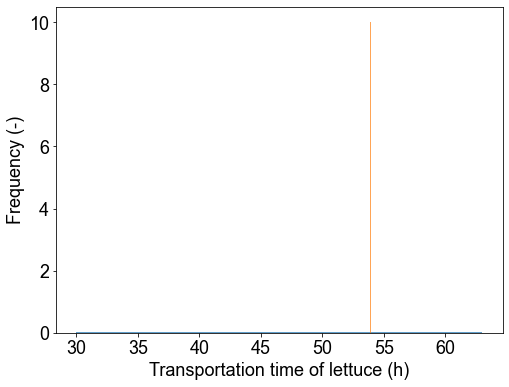

In [87]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["time_trans_lettuce"][Sim_results["time_trans_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["time_trans_lettuce"][Sim_results["time_trans_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Transportation time of lettuce (h)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Transportation time of lettuce.pdf", bbox_inches="tight", dpi=500)

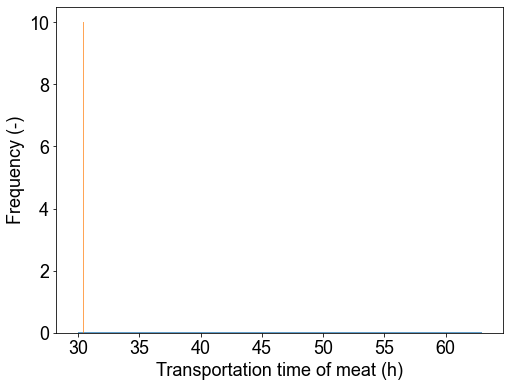

In [88]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["time_trans_meat"][Sim_results["time_trans_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["time_trans_meat"][Sim_results["time_trans_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Transportation time of meat (h)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Transportation time of meat.pdf", bbox_inches="tight", dpi=500)

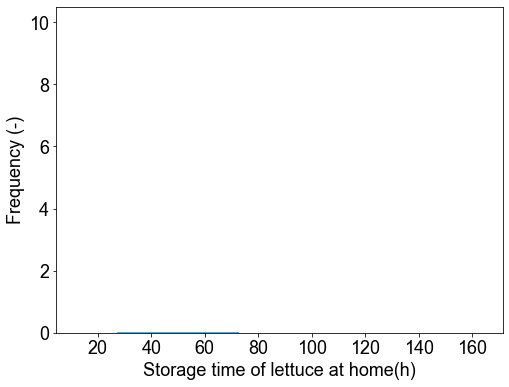

In [89]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["time_home_lettuce"][Sim_results["time_home_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["time_home_lettuce"][Sim_results["time_home_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Storage time of lettuce at home(h)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Storage time of lettuce at home.pdf", bbox_inches="tight", dpi=500)

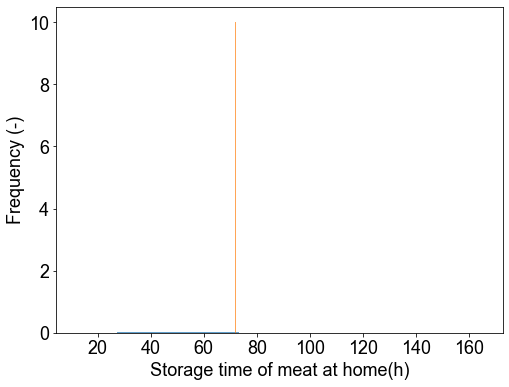

In [90]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["time_home_meat"][Sim_results["time_home_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["time_home_meat"][Sim_results["time_home_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Storage time of meat at home(h)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Storage time of meat at home.pdf", bbox_inches="tight", dpi=500)

In [91]:
time_after_process_lettuce = Sim_results["time_trans_lettuce"] + Sim_results["time_home_lettuce"]
time_after_process_meat = Sim_results["time_trans_meat"] + Sim_results["time_home_meat"]
time_after_process_lettuce_ill = Sim_results_ill["time_trans_lettuce"] + Sim_results_ill["time_home_lettuce"]
time_after_process_meat_ill = Sim_results_ill["time_trans_meat"] + Sim_results_ill["time_home_meat"]

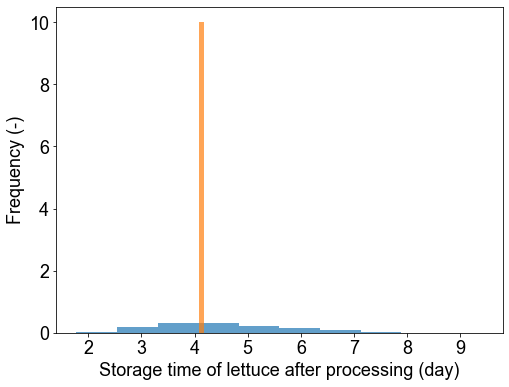

In [92]:
fig = plt.figure(figsize =(8,6))
plt.hist(time_after_process_lettuce[time_after_process_lettuce!=-np.inf]/24,density=True, alpha =0.7)
plt.hist(time_after_process_lettuce_ill[time_after_process_lettuce_ill!=-np.inf]/24,density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Storage time of lettuce after processing (day)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Storage time of lettuce after processing.pdf", bbox_inches="tight", dpi=500)

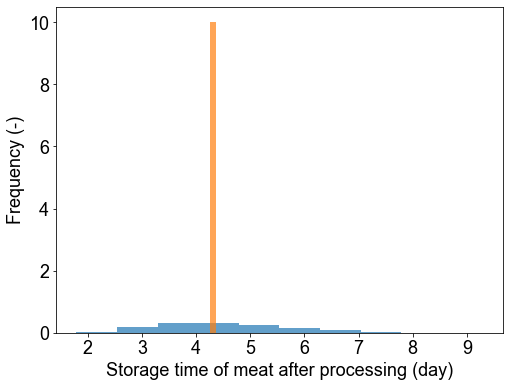

In [93]:
fig = plt.figure(figsize =(8,6))
plt.hist(time_after_process_meat[time_after_process_meat!=-np.inf]/24,density=True, alpha =0.7)
plt.hist(time_after_process_meat_ill[time_after_process_meat_ill!=-np.inf]/24,density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Storage time of meat after processing (day)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Storage time of meat after processing.pdf", bbox_inches="tight", dpi=500)

In [94]:
np.sum(Sim_results["checklettuce0"])

12534

In [95]:
np.sum(Sim_results["checkmeat0"])

107871

In [96]:
np.sum(Sim_results["checkhandwash"])

395066

(0.0, 1.0)

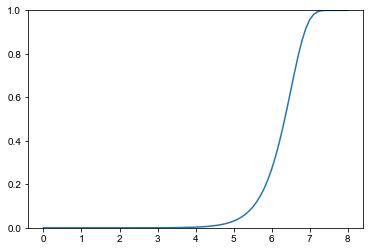

In [97]:
logdds = np.linspace(0, 8, int(8*10+1), endpoint = True)
probss = np.linspace(0, 8, int(8*10+1), endpoint = True)
for i in range (len(logdds)):
    probss[i] = DRmodel(10**logdds[i])
plt.plot(logdds, probss)
plt.ylim([0,1])

In [98]:
#生肉を先に調理しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuceaftermeat"]==1])

3.133233455597405e-06

In [99]:
#レタスを先に調理しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuceaftermeat"]==0])

3.4557835319415268e-06

In [100]:
#レタスを洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettucewash"]==1])

1.566664480392078e-06

In [101]:
#レタスを洗っていないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettucewash"]==0])

6.415890223553315e-06

In [102]:
#手を洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkhandwash"]==1])

3.257430404033699e-06

In [103]:
#手を洗っていないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkhandwash"]==0])

3.5752321238393265e-06

In [104]:
#レタスが汚染しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuce0"]==1])

0.00013296633157810478

In [105]:
#レタスが汚染していないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuce0"]==0])

1.880333264840112e-07

In [106]:
#生肉が汚染しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkmeat0"]==1])

4.05020811895684e-06

In [107]:
#生肉が汚染していないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkmeat0"]==0])

3.1548359328369183e-06

In [29]:
#レタスを先に調理して、手を洗っていて、レタスを洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][(Sim_results["checklettuceaftermeat"]==0)&(Sim_results["checkhandwash"]==1)&(Sim_results["checklettucewash"]==1)])

1.3238193005548456e-06

In [30]:
#手を洗っていて、レタスを洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][(Sim_results["checkhandwash"]==1)&(Sim_results["checklettucewash"]==1)])

1.5006272526334655e-06

Progress:   0%|          | 0/301 [00:00<?, ?it/s]

Progress:   0%|          | 0/301 [00:00<?, ?it/s]

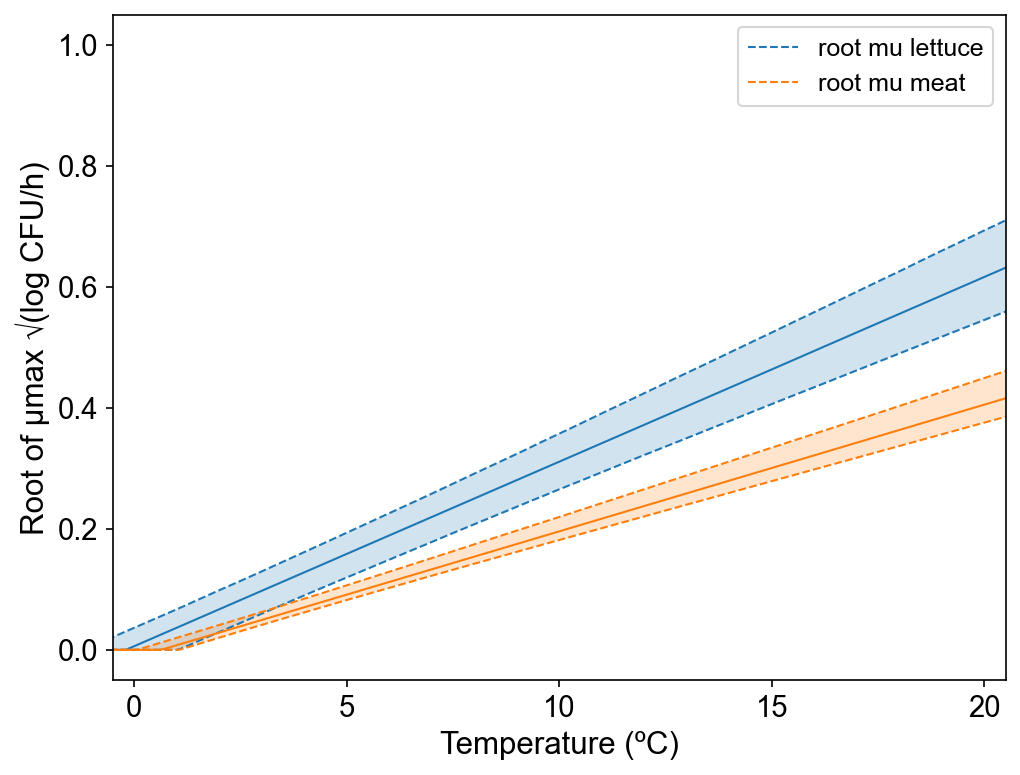

In [96]:
temp_min = -5
temp_max = 25
devide = (temp_max-temp_min)*10
temp_interval = np.arange(temp_min, temp_max*(devide+1)/devide, (temp_max-temp_min)/devide, dtype="float")
root_mu_conf_mcmc = np.zeros((len(temp_interval),rep_sim), dtype=float)
root_mu_conf_mcmc_quantile_lettuce = np.zeros((len(temp_interval), 3), dtype=float)

for j in tqdm(range(len(temp_interval)),desc='Progress', leave=False):
    for k in range(rep_sim):
        if (temp_interval[j]-Sim_results["d_growth_lettuce"][k]) > 0:
            root_mu_conf_mcmc[j,k] = Sim_results["c_growth_lettuce"][k] * (temp_interval[j]-Sim_results["d_growth_lettuce"][k])
        else:
            root_mu_conf_mcmc[j,k] = 0
    root_mu_conf_mcmc_quantile_lettuce[j,:] = np.quantile(root_mu_conf_mcmc[j,:],[0.025,  0.5, 0.975])

pdf = PdfPages("plot/mu.pdf")
plt.figure(figsize=[6.4*1.2, 4.8*1.2], dpi=150)
plt.rcParams["font.family"] = "Arial"

plt.xticks(size=14)
plt.yticks(size=14)
plt.xlabel("Temperature (ºC)",size=15,fontname="Arial")
plt.ylabel("Root of µmax √(log CFU/h)",size=15,fontname="Arial")
plt.xticks(np.arange(-0, 21, 5))
plt.ylim([-0.05,1.05])
plt.xlim([-0.5,20.5])

Palette=sns.color_palette(n_colors = 3)
plt.fill_between(temp_interval, root_mu_conf_mcmc_quantile_lettuce[:,0], root_mu_conf_mcmc_quantile_lettuce[:,2], facecolor=Palette[0], alpha=0.2)
plt.plot(temp_interval, root_mu_conf_mcmc_quantile_lettuce[:,0], lw=1, color=Palette[0], linestyle='--')
plt.plot(temp_interval, root_mu_conf_mcmc_quantile_lettuce[:,2], lw=1, color=Palette[0], linestyle='--', label="root mu lettuce")
plt.plot(temp_interval, root_mu_conf_mcmc_quantile_lettuce[:,1], lw=1, color=Palette[0])






temp_min = -5
temp_max = 25
devide = (temp_max-temp_min)*10
temp_interval = np.arange(temp_min, temp_max*(devide+1)/devide, (temp_max-temp_min)/devide, dtype="float")
root_mu_conf_mcmc = np.zeros((len(temp_interval),rep_sim), dtype=float)
root_mu_conf_mcmc_quantile_meat = np.zeros((len(temp_interval), 3), dtype=float)

for j in tqdm(range(len(temp_interval)),desc='Progress', leave=False):
    for k in range(rep_sim):
        if (temp_interval[j]-Sim_results["d_growth_meat"][k]) > 0:
            root_mu_conf_mcmc[j,k] = Sim_results["c_growth_meat"][k] * (temp_interval[j]-Sim_results["d_growth_meat"][k])
        else:
            root_mu_conf_mcmc[j,k] = 0
    root_mu_conf_mcmc_quantile_meat[j,:] = np.quantile(root_mu_conf_mcmc[j,:],[0.025,  0.5, 0.975])

plt.xlabel("Temperature (ºC)",size=15,fontname="Arial")
plt.ylabel("Root of µmax √(log CFU/h)",size=15,fontname="Arial")
plt.xticks(np.arange(-0, 21, 5))
plt.ylim([-0.05,1.05])
plt.xlim([-0.5,20.5])


plt.fill_between(temp_interval, root_mu_conf_mcmc_quantile_meat[:,0], root_mu_conf_mcmc_quantile_meat[:,2], facecolor=Palette[1], alpha=0.2)
plt.plot(temp_interval, root_mu_conf_mcmc_quantile_meat[:,0], lw=1, color=Palette[1], linestyle='--')
plt.plot(temp_interval, root_mu_conf_mcmc_quantile_meat[:,2], lw=1, color=Palette[1], linestyle='--', label="root mu meat")
plt.plot(temp_interval, root_mu_conf_mcmc_quantile_meat[:,1], lw=1, color=Palette[1])

plt.legend(fontsize=12)

pdf.savefig()
pdf.close()
plt.show()